# **Project Name**    - Predicting E-Commerce Customer Satisfaction (CSAT) with Deep Learning ANNs

##### **Project Type**    - Classification (multi-class, ordinal target) with Deep Learning / ANN, EDA, Hypothesis Testing & Local Deployment
##### **Contribution**    - Individual / Team
##### **Team Member 1 -** <add name>
##### **Team Member 2 -** <add name>
##### **Team Member 3 -** <add name>
##### **Team Member 4 -** <add name>

# **Project Summary -**

**Business problem.** Shopzilla, an e-commerce platform, handled about 86,000 customer-support tickets in one month (28 Jul - 31 Aug 2023) across inbound calls, outbound calls and e-mail. The company only learns how a customer felt after a survey is returned, which is too late to rescue an unhappy customer. This project builds a deep-learning ANN that estimates the CSAT score (1-5) and, more importantly, the probability that a ticket ends in dissatisfaction (CSAT <= 2), using only information that exists while the ticket is still being worked.

**Data and cleaning.** The dataset has 85,907 rows and 20 columns, with no duplicates and no missing target. Missingness is structural: about 80 % of tickets are not linked to an order, so order date, price, product and city are empty by design; `connected_handling_time` is 99.7 % missing and was dropped. Dates arrive as strings in two formats and were parsed; 3,128 rows have a response logged before the report (clipped to zero and flagged). Customer remarks are written together with the survey answer, so they would be target leakage and were excluded from the production model. The target is J-shaped and imbalanced: 69.4 % of customers give 5.

**EDA and hypotheses.** Eighteen charts (univariate, bivariate, multivariate) show that response time is the strongest operational driver: dissatisfaction rises from 8.9 % when the first answer comes within 5 minutes to 36.3 % beyond 24 hours. E-mail (23.2 % dissatisfied vs about 14 % on phone), order-linked tickets (21.5 % vs 12.8 %), Furniture/Mobile/Appliances products (about 30 %), trainee agents (16.6 %) and the Morning shift stand out, and agent-to-agent variation is about twice what chance would produce. Three hypothesis tests (two-proportion z-test, chi-square, Mann-Whitney U) confirm the response-time, channel and tenure effects at alpha = 0.05.

**Feature engineering and models.** Features include log response time, calendar and survey-lag variables, order-context flags, log price, one-hot or learned embeddings for the categoricals, and a smoothed out-of-fold agent target encoding that avoids leakage. Three models were built on an 80/20 stratified split with early stopping, class-weighted training, random-search tuning and 3-fold cross-validation with preprocessing refitted per fold: a logistic regression baseline, a dense ANN, and an innovative embedding + residual ANN with an optional ordinal-aware loss. Metrics are macro-F1, quadratic weighted kappa, MAE, and the ROC-AUC and top-20 % recall of the dissatisfaction detector, because accuracy is misleading when always answering "5" gives 69 %.

**Results (hold-out test).** The three models are statistically indistinguishable. The embedding ANN reaches ROC-AUC 0.734, QWK 0.283 and macro-F1 0.262 after class re-weighting (the always-5 baseline has AUC 0.5 and macro-F1 0.164); the dense ANN and logistic regression are within 0.002 AUC. Hyper-parameter tuning gave no meaningful gain. Even so, the risk score is useful: the riskiest decile of tickets has a 39.3 % dissatisfaction rate versus 3.0 % in the safest decile, and the top 20 % of flagged tickets contain 44.5 % of all dissatisfied customers. Permutation importance ranks response time first, then sub-category, agent history and order context. An upper-bound experiment shows that adding the customer's own remarks (not available in real time) lifts AUC to 0.806, so much of the remaining unpredictability is the voice of the customer.

**Deployment and recommendations.** The model, preprocessor and metadata are saved with joblib/Keras, scored through a standalone `predict.py` (verified to reproduce in-memory predictions) and a small Streamlit demo. Recommended actions: set a first-response SLA (the model implies average predicted dissatisfaction rising from about 18 % at 2 minutes to 37 % at 24 hours), escalate HIGH-risk tickets, review e-mail handling, and coach trainee and Morning-shift teams. The main limitation is honest: ticket metadata alone caps performance at a moderate level.

# **GitHub Link -**

<paste your GitHub repository link here>  (suggested repo layout: `notebook/`, `data/`, `deployment/`, `README.md`)

# **Problem Statement**

**Shopzilla's customer-support team handles ~86,000 tickets a month across e-mail, inbound and outbound-call channels, but it only learns how a customer felt *after* the customer fills in a survey - and only a fraction of customers do. By then the unhappy customer has already been lost. We need a model that estimates the CSAT score (1-5) of an interaction from the information available about the ticket itself, so that at-risk interactions (CSAT 1-2) can be flagged, investigated and recovered quickly, and so the business learns *which operational levers move satisfaction*.**

#### **Define Your Business Objective?**

1. **Early-warning:** rank every ticket by the probability that the customer will be dissatisfied (CSAT <= 2) so supervisors can intervene on the riskiest ones first.
2. **Prediction:** predict the CSAT score (1-5) with a deep-learning ANN and compare it honestly against simpler baselines.
3. **Insight:** quantify the drivers (response time, channel, issue type, product, agent/tenure) so that staffing, SLA and training decisions are evidence-based.
4. **Deployment:** package the model so it can score new tickets locally in real time.

**Design decisions that matter (explained in detail later):**
* The free-text *Customer Remarks* are written **together with** the survey answer, so they would not exist at the moment we want to predict. Using them would be target leakage. The production model therefore **excludes** them; they are used only in a clearly-labelled "upper-bound" experiment.
* CSAT is heavily imbalanced (69 % are 5s), so plain accuracy is misleading (a model that always says "5" gets 69 %). We therefore judge models on **macro-F1, quadratic weighted kappa, MAE and the ROC-AUC of the "dissatisfied" detector**.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os, sys, time, json, warnings, random
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # keep TensorFlow logs quiet

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score, mean_absolute_error,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report, make_scorer)
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---- reproducibility -------------------------------------------------------
SEED = 42
random.seed(SEED); np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception as e:                              # not fatal: only affects bit-for-bit reproducibility
    print("Determinism not enabled:", e)

sns.set_theme(style="whitegrid", context="notebook")
BLUE, ORANGE, GREY, RED = "#2f6db5", "#e8833a", "#8c8c8c", "#c0392b"
pd.set_option("display.max_columns", 50)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| pandas", pd.__version__)

I0000 00:00:1791993480.969238      94 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791993511.411419      94 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1 | pandas 3.0.2


### Shared feature-engineering module

All feature engineering and preprocessing lives in a real Python module (`csat_utils.py`), written below. This is a deliberate production choice: the fitted preprocessor is saved with `joblib` and must be re-loadable in a **different process** (the local deployment script), which only works if its classes live in an importable module rather than inside the notebook. It also guarantees training and serving use *identical* logic.

In [2]:
%%writefile csat_utils.py
"""csat_utils.py - feature engineering + preprocessing for the Shopzilla CSAT project.

Kept in a real module (not notebook-only code) so that the fitted preprocessor
saved with joblib can be loaded again in a separate process (e.g. predict.py).
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

# --------------------------------------------------------------------------
# Column groups
# --------------------------------------------------------------------------
CAT_COLS = ["channel_name", "category", "Sub-category", "Product_category",
            "Tenure Bucket", "Agent Shift", "Manager", "Supervisor", "Customer_City"]
NUM_COLS = ["response_min", "log_response_min", "resp_negative_flag", "rep_hour", "rep_dow",
            "rep_day", "is_weekend", "survey_lag_days", "has_order_info",
            "order_to_issue_days", "log_item_price", "has_order_id"]
AGENT_COL = "Agent_name"
RAW_INPUT_COLS = ["channel_name", "category", "Sub-category", "Customer Remarks", "Order_id",
                  "order_date_time", "Issue_reported at", "issue_responded", "Survey_response_Date",
                  "Customer_City", "Product_category", "Item_price", "Agent_name", "Supervisor",
                  "Manager", "Tenure Bucket", "Agent Shift"]


# --------------------------------------------------------------------------
# Feature engineering (row-level only -> safe for real-time scoring)
# --------------------------------------------------------------------------
def engineer(raw: pd.DataFrame) -> pd.DataFrame:
    """Turn raw ticket rows into model-ready features. No target information is used."""
    d = pd.DataFrame(index=raw.index)
    rep = pd.to_datetime(raw["Issue_reported at"], format="%d/%m/%Y %H:%M", errors="coerce")
    resp = pd.to_datetime(raw["issue_responded"], format="%d/%m/%Y %H:%M", errors="coerce")
    survey = pd.to_datetime(raw["Survey_response_Date"], format="%d-%b-%y", errors="coerce")
    order = pd.to_datetime(raw["order_date_time"], format="%d/%m/%Y %H:%M", errors="coerce")

    # Responsiveness: the single most important operational driver (see EDA).
    rt = (resp - rep).dt.total_seconds() / 60.0
    d["resp_negative_flag"] = (rt < 0).astype(int)          # data-entry anomaly (responded before reported)
    d["response_min"] = rt.clip(lower=0).fillna(0)
    d["log_response_min"] = np.log1p(d["response_min"])

    # Calendar features
    d["rep_hour"] = rep.dt.hour.fillna(12)
    d["rep_dow"] = rep.dt.dayofweek.fillna(0)
    d["rep_day"] = rep.dt.day.fillna(15)
    d["is_weekend"] = (d["rep_dow"] >= 5).astype(int)
    d["survey_lag_days"] = (survey - rep.dt.normalize()).dt.days.clip(-5, 31).fillna(0)

    # Order information (missing for ~80% of tickets = not order-linked)
    d["has_order_info"] = order.notna().astype(int)
    d["order_to_issue_days"] = ((rep - order).dt.total_seconds() / 86400).clip(0, 400).fillna(0)
    d["log_item_price"] = np.log1p(pd.to_numeric(raw["Item_price"], errors="coerce").fillna(0).clip(lower=0))
    d["has_order_id"] = raw["Order_id"].notna().astype(int)

    # Categoricals (missing -> explicit 'Unknown' level)
    for c in CAT_COLS:
        d[c] = raw[c].fillna("Unknown").astype(str).str.strip()
    d[AGENT_COL] = raw[AGENT_COL].fillna("Unknown").astype(str)
    return d


# --------------------------------------------------------------------------
# Agent-level target encoding (out-of-fold, smoothed) - 1,371 agents is too many for one-hot
# --------------------------------------------------------------------------
class AgentStats(BaseEstimator, TransformerMixin):
    """Smoothed historical agent performance.

    Outputs [agent_low_rate, agent_mean_csat, log_agent_volume].
    fit_transform uses K-fold out-of-fold encoding so a row never sees its own label (no leakage).
    """

    def __init__(self, smoothing=20, n_splits=5, random_state=42):
        self.smoothing = smoothing
        self.n_splits = n_splits
        self.random_state = random_state

    def _stats(self, agents, y):
        df = pd.DataFrame({"a": np.asarray(agents).ravel(), "low": (y <= 2).astype(float), "s": y.astype(float)})
        g = df.groupby("a").agg(n=("low", "size"), low=("low", "sum"), s=("s", "sum"))
        return g

    def _encode(self, agents, g, prior_low, prior_s):
        a = pd.Series(np.asarray(agents).ravel())
        n = a.map(g["n"]).fillna(0).to_numpy()
        low = a.map(g["low"]).fillna(0).to_numpy()
        s = a.map(g["s"]).fillna(0).to_numpy()
        m = self.smoothing
        return np.c_[(low + m * prior_low) / (n + m), (s + m * prior_s) / (n + m), np.log1p(n)]

    def fit(self, X, y):
        y = np.asarray(y)
        self.prior_low_ = float((y <= 2).mean())
        self.prior_s_ = float(y.mean())
        self.stats_ = self._stats(X, y)
        return self

    def fit_transform(self, X, y=None, **kw):
        y = np.asarray(y)
        self.fit(X, y)
        X = np.asarray(X).ravel()
        out = np.zeros((len(X), 3))
        for tr, va in KFold(self.n_splits, shuffle=True, random_state=self.random_state).split(X):
            g = self._stats(X[tr], y[tr])
            out[va] = self._encode(X[va], g, self.prior_low_, self.prior_s_)
        return out

    def transform(self, X):
        return self._encode(X, self.stats_, self.prior_low_, self.prior_s_)


def _shift_one(x):
    """OrdinalEncoder gives -1 to unseen levels; shift so 0 = unknown/rare, 1.. = real levels."""
    return x + 1


# --------------------------------------------------------------------------
# Preprocessors
# --------------------------------------------------------------------------
def make_dense_preprocessor(extra_num=()):
    """One-hot (rare levels pooled) + scaled numerics + agent stats -> dense matrix for sklearn / MLP."""
    num = list(NUM_COLS) + list(extra_num)
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), CAT_COLS),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("agent", Pipeline([("enc", AgentStats()), ("sc", StandardScaler())]), [AGENT_COL]),
    ])


def make_embed_preprocessor(extra_num=()):
    """Integer codes for embedding layers (first len(CAT_COLS) columns) + scaled numerics + agent stats."""
    num = list(NUM_COLS) + list(extra_num)
    return ColumnTransformer([
        ("cat", Pipeline([("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                 encoded_missing_value=-1, min_frequency=100)),
                          ("shift", FunctionTransformer(_shift_one))]), CAT_COLS),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("agent", Pipeline([("enc", AgentStats()), ("sc", StandardScaler())]), [AGENT_COL]),
    ])


# --------------------------------------------------------------------------
# Wrapper that couples a fitted preprocessor with a Keras model -> predict_proba(DataFrame)
# --------------------------------------------------------------------------
class AnnPipeline:
    def __init__(self, pre, model, kind="dense", n_cat=0, class_weights=None, offsets=None):
        self.pre, self.model, self.kind, self.n_cat = pre, model, kind, n_cat
        self.offsets = None if offsets is None else np.asarray(offsets, dtype="int32")
        self.class_weights = np.ones(5) if class_weights is None else np.asarray(class_weights)

    def _inputs(self, X):
        Xt = self.pre.transform(X)
        if self.kind == "embed":
            cats = Xt[:, :self.n_cat].astype("int32")
            if self.offsets is not None:          # one shared embedding table -> shift each column into its own id range
                cats = cats + self.offsets
            return [cats, Xt[:, self.n_cat:].astype("float32")]
        return Xt.astype("float32")

    def predict_proba(self, X):
        return np.asarray(self.model.predict(self._inputs(X), batch_size=4096, verbose=0))

    def predict(self, X):
        """Predicted CSAT (1-5) after optional per-class probability re-weighting."""
        return (self.predict_proba(X) * self.class_weights).argmax(1) + 1

Overwriting csat_utils.py


In [3]:
import importlib, csat_utils
importlib.reload(csat_utils)
from csat_utils import (engineer, make_dense_preprocessor, make_embed_preprocessor, AnnPipeline,
                        CAT_COLS, NUM_COLS, AGENT_COL)
print("csat_utils imported OK")

csat_utils imported OK


### Dataset Loading

In [4]:
# Load Dataset (works locally, in the project sandbox and in Google Colab)
CANDIDATE_PATHS = ["/mnt/user-data/uploads/eCommerce_Customer_support_data.csv",
                   "eCommerce_Customer_support_data.csv", "data/eCommerce_Customer_support_data.csv"]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)

if DATA_PATH is None:                                # Colab fallback: ask for an upload
    try:
        from google.colab import files
        files.upload()
        DATA_PATH = "eCommerce_Customer_support_data.csv"
    except ImportError:
        raise FileNotFoundError("Place eCommerce_Customer_support_data.csv next to this notebook.")

raw = pd.read_csv(DATA_PATH)
print("Loaded from:", DATA_PATH)

Loaded from: /mnt/user-data/uploads/eCommerce_Customer_support_data.csv


### Dataset First View

In [5]:
# Dataset First Look
raw.head()

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01/08/2023 11:13,01/08/2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01/08/2023 12:52,01/08/2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01/08/2023 20:16,01/08/2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01/08/2023 20:56,01/08/2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01/08/2023 10:30,01/08/2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


### Dataset Rows & Columns count

In [6]:
# Dataset Rows & Columns count
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")

Rows: 85,907 | Columns: 20


### Dataset Information

In [7]:
# Dataset Info
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  str    
 1   channel_name             85907 non-null  str    
 2   category                 85907 non-null  str    
 3   Sub-category             85907 non-null  str    
 4   Customer Remarks         28742 non-null  str    
 5   Order_id                 67675 non-null  str    
 6   order_date_time          17214 non-null  str    
 7   Issue_reported at        85907 non-null  str    
 8   issue_responded          85907 non-null  str    
 9   Survey_response_Date     85907 non-null  str    
 10  Customer_City            17079 non-null  str    
 11  Product_category         17196 non-null  str    
 12  Item_price               17206 non-null  float64
 13  connected_handling_time  242 non-null    float64
 14  Agent_name               85907 no

#### Duplicate Values

In [8]:
# Dataset Duplicate Value Count
print("Fully duplicated rows      :", raw.duplicated().sum())
print("Duplicated 'Unique id'     :", raw["Unique id"].duplicated().sum())
print("Duplicated 'Order_id' (non-null):", raw["Order_id"].dropna().duplicated().sum(),
      "-> one order can legitimately have several tickets, so these are NOT removed")

Fully duplicated rows      : 0
Duplicated 'Unique id'     : 0
Duplicated 'Order_id' (non-null): 0 -> one order can legitimately have several tickets, so these are NOT removed


#### Missing Values/Null Values

In [9]:
# Missing Values/Null Values Count
miss = pd.DataFrame({"missing": raw.isna().sum(), "pct": (raw.isna().mean() * 100).round(2)})
miss[miss.missing > 0].sort_values("pct", ascending=False)

,missing,pct
connected_handling_time,85665,99.72
Customer_City,68828,80.12
Product_category,68711,79.98
Item_price,68701,79.97
order_date_time,68693,79.96
Customer Remarks,57165,66.54
Order_id,18232,21.22


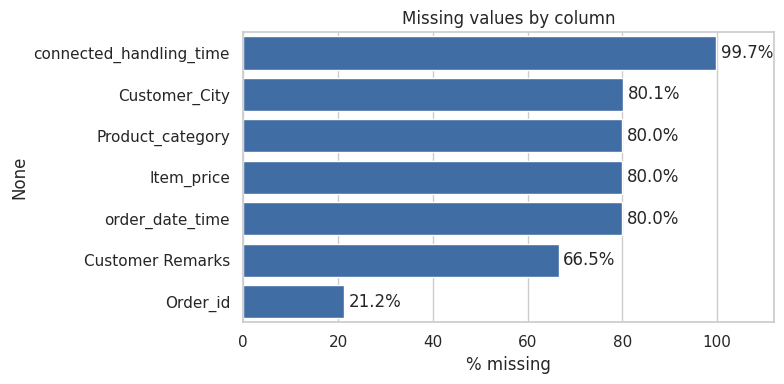

In [10]:
# Visualizing the missing values
m = (raw.isna().mean() * 100).sort_values(ascending=False)
m = m[m > 0]
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=m.values, y=m.index, color=BLUE, ax=ax)
for i, v in enumerate(m.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, 112); ax.set_xlabel("% missing"); ax.set_title("Missing values by column")
plt.tight_layout(); plt.show()

### What did you know about your dataset?

* **85,907 tickets x 20 columns**, one month of Shopzilla support interactions (reported 28 Jul - 31 Aug 2023, surveyed 1-31 Aug 2023). The target `CSAT Score` has **no missing values**.
* **No duplicate rows and `Unique id` is truly unique**, so no records had to be removed. `Order_id` repeats a little (several tickets about one order), which is legitimate.
* **Missingness is structural, not random.** `Order_id` is missing for ~21 % of tickets; `order_date_time`, `Item_price`, `Product_category` and `Customer_City` are missing for ~80 % - these are tickets *not linked to an order* (e.g. general queries). `connected_handling_time` is missing for 99.7 % (only 242 values) and is useless as a feature. `Customer Remarks` is missing for 67 % simply because most customers do not write a comment.
* The target is **highly imbalanced and J-shaped**: ~69 % of customers give 5, ~13 % give 4, ~13 % give 1, and the middle scores (2 and 3) are rare.
* Date columns are stored as **strings in two different formats** (`dd/mm/yyyy hh:mm` and `dd-Mon-yy`) and must be parsed.
* `issue_responded` is *earlier* than `Issue_reported at` in ~3,100 rows - a data-quality anomaly we must handle explicitly.

## ***2. Understanding Your Variables***

In [11]:
# Dataset Columns
list(raw.columns)

['Unique id',
 'channel_name',
 'category',
 'Sub-category',
 'Customer Remarks',
 'Order_id',
 'order_date_time',
 'Issue_reported at',
 'issue_responded',
 'Survey_response_Date',
 'Customer_City',
 'Product_category',
 'Item_price',
 'connected_handling_time',
 'Agent_name',
 'Supervisor',
 'Manager',
 'Tenure Bucket',
 'Agent Shift',
 'CSAT Score']

In [12]:
# Dataset Describe
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unique id,85907,85907,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_name,85907,3,Inbound,68142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,85907,12,Returns,44097,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sub-category,85907,57,Reverse Pickup Enquiry,22389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Remarks,28742,18231,Good,1390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_id,67675,67675,c27c9bb4-fa36-4140-9f1f-21009254ffdb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date_time,17214,13766,09/08/2023 11:55,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Issue_reported at,85907,30923,13/08/2023 10:40,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
issue_responded,85907,30262,28/08/2023 00:00,3378,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Survey_response_Date,85907,31,28-Aug-23,3452,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description

| Variable | Meaning | Type / note |
|---|---|---|
| Unique id | Ticket identifier | ID - not predictive, dropped |
| channel_name | Inbound call / Outcall / Email | categorical (3) |
| category, Sub-category | Issue type (12 / 57 levels) | categorical; Sub-category is long-tailed |
| Customer Remarks | Free-text comment written with the survey | text - **leakage risk**, excluded from the production model |
| Order_id | Order the ticket refers to | ID - only its presence is informative |
| order_date_time | When the order was placed | datetime, 80 % missing (non-order tickets) |
| Issue_reported at / issue_responded | When the customer raised the issue / support responded | datetime -> response time |
| Survey_response_Date | Day the survey was answered | datetime -> survey lag |
| Customer_City, Product_category, Item_price | Order context | mostly missing, informative when present |
| connected_handling_time | Call handling time | 99.7 % missing - dropped |
| Agent_name, Supervisor, Manager | Staff hierarchy (1,371 / 40 / 6) | high-cardinality categorical |
| Tenure Bucket, Agent Shift | Agent experience and shift | categorical |
| **CSAT Score** | **Target, 1-5** | ordinal integer, imbalanced |

### Check Unique Values for each variable.

In [13]:
# Check Unique Values for each variable.
pd.DataFrame({"n_unique": raw.nunique(), "dtype": raw.dtypes.astype(str)}).sort_values("n_unique")

,n_unique,dtype
channel_name,3,str
CSAT Score,5,int64
Agent Shift,5,str
Tenure Bucket,5,str
Manager,6,str
Product_category,9,str
category,12,str
Survey_response_Date,31,str
Supervisor,40,str
Sub-category,57,str


## 3. ***Data Wrangling***

### Data Wrangling Code

In [14]:
# Write your code to make your dataset analysis ready.
y = raw["CSAT Score"].astype(int).values            # target: 1..5
feat = engineer(raw)                                  # all features, built in csat_utils.py (no target information used)

# Analysis frame for EDA = engineered features + target + a few readable helper columns
eda = feat.copy()
eda["CSAT"] = y
eda["low"] = (eda["CSAT"] <= 2).astype(int)           # 'dissatisfied' flag used throughout the EDA
eda["reported_at"] = pd.to_datetime(raw["Issue_reported at"], format="%d/%m/%Y %H:%M")
eda["survey_date"] = pd.to_datetime(raw["Survey_response_Date"], format="%d-%b-%y")
eda["rt_bucket"] = pd.cut(eda["response_min"], [-1, 5, 15, 60, 240, 1440, 1e9],
                          labels=["0-5 min", "5-15 min", "15-60 min", "1-4 h", "4-24 h", ">24 h"])

print("Engineered feature frame:", feat.shape)
print("Responses logged before the issue was reported:", int(feat.resp_negative_flag.sum()),
      f"({feat.resp_negative_flag.mean():.1%}) -> clipped to 0 min and flagged")
print("Overall dissatisfaction rate (CSAT<=2): {:.1%}".format(eda.low.mean()))
feat.head(3).T

Engineered feature frame: (85907, 22)
Responses logged before the issue was reported: 3128 (3.6%) -> clipped to 0 min and flagged
Overall dissatisfaction rate (CSAT<=2): 14.6%


,0,1,2
resp_negative_flag,0,0,0
response_min,34.0,2.0,22.0
log_response_min,3.555348,1.098612,3.135494
rep_hour,11,12,20
rep_dow,1,1,1
rep_day,1,1,1
is_weekend,0,0,0
survey_lag_days,0,0,0
has_order_info,0,0,0
order_to_issue_days,0.0,0.0,0.0


### What all manipulations have you done and insights you found?

1. **Parsed all four timestamp columns** with their explicit formats (zero parse failures for the three always-present ones; `order_date_time` is legitimately empty for 80 % of rows).
2. **Response time** = `issue_responded - Issue_reported at` in minutes. 3,128 rows (3.6 %) are negative (response before report): physically impossible, so we **clip to 0 and add a `resp_negative_flag`** instead of dropping rows - the flag lets the model learn whether the anomaly carries information (it does not look dangerous: those tickets are mostly satisfied).
3. **Calendar features:** reported hour, weekday, day-of-month, weekend flag, and the **survey lag** (days between report and survey).
4. **Order context:** a flag for "ticket linked to an order", days between order and issue, `log1p(Item_price)`, flag for order id present. Missing numeric values become 0 *plus* an explicit flag, because "missing" means "not an order ticket" - that is information, not noise.
5. **Categorical gaps** become an explicit `Unknown` level.
6. **Dropped:** `Unique id`, `Order_id` (pure identifiers), `connected_handling_time` (99.7 % missing), the raw timestamps (replaced by derived features) and `Customer Remarks` (leakage, see below).
7. **No rows were removed**, so no information was lost.

**Key early insight:** the median response time is 5 minutes, but the long tail is huge (max ~4 days), and the dissatisfaction rate climbs from ~9 % for 0-5 min responses to ~36 % for responses slower than 24 h (Chart 8).

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

Following the **UBM rule**: Charts 1-5 are *Univariate*, 6-15 are *Bivariate* and 16-18 are *Multivariate*. "Dissatisfied" always means **CSAT <= 2** (14.6 % of tickets). A few helper functions keep the chart code short.

In [15]:
# Helpers used by the bivariate charts
GLOBAL_LOW = eda["low"].mean()

def rate_table(col, order=None):
    """Dissatisfaction rate, ticket count and 95% CI per level of `col`."""
    g = eda.groupby(col, observed=True)["low"].agg(["mean", "size"]).rename(columns={"mean": "rate", "size": "n"})
    g["ci"] = 1.96 * np.sqrt(g["rate"] * (1 - g["rate"]) / g["n"])
    return g.loc[order] if order is not None else g.sort_values("rate")

def rate_bar(col, order=None, horizontal=False, title="", figsize=(8, 4), min_n=0):
    g = rate_table(col, order)
    g = g[g.n >= min_n]
    fig, ax = plt.subplots(figsize=figsize)
    x = g["rate"] * 100; e = g["ci"] * 100
    if horizontal:
        ax.barh(g.index.astype(str), x, xerr=e, color=BLUE, capsize=3)
        ax.axvline(GLOBAL_LOW * 100, color=RED, ls="--", label=f"overall {GLOBAL_LOW:.1%}")
        for i, (v, n) in enumerate(zip(x, g.n)): ax.text(v + e.iloc[i] + .5, i, f"n={n:,}", va="center", fontsize=8)
        ax.set_xlabel("% dissatisfied (CSAT<=2)")
    else:
        ax.bar(g.index.astype(str), x, yerr=e, color=BLUE, capsize=3)
        ax.axhline(GLOBAL_LOW * 100, color=RED, ls="--", label=f"overall {GLOBAL_LOW:.1%}")
        for i, (v, n) in enumerate(zip(x, g.n)): ax.text(i, v + e.iloc[i] + .4, f"n={n:,}", ha="center", fontsize=8)
        ax.set_ylabel("% dissatisfied (CSAT<=2)")
    ax.set_title(title); ax.legend(); plt.tight_layout(); plt.show()
    return g

#### Chart - 1: Distribution of the target (CSAT Score)  [Univariate]

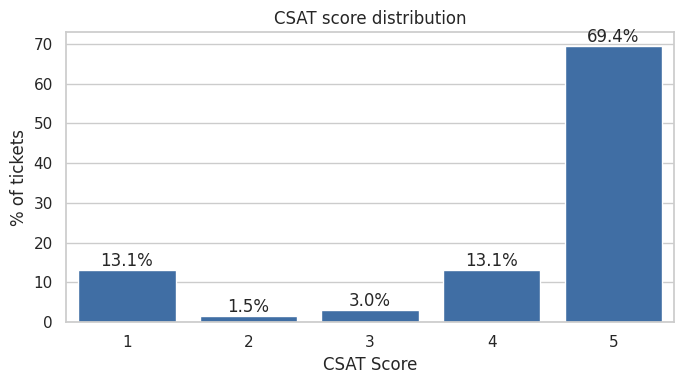

In [16]:
# Chart - 1 visualization code
s = eda["CSAT"].value_counts(normalize=True).sort_index() * 100
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=s.index, y=s.values, color=BLUE, ax=ax)
for i, v in enumerate(s.values): ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_xlabel("CSAT Score"); ax.set_ylabel("% of tickets"); ax.set_title("CSAT score distribution")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is the clearest way to show the shape of a small discrete, ordinal target. Knowing the class balance is the first thing to settle before choosing a loss function and metrics.

##### 2. What is/are the insight(s) found from the chart?

The distribution is **J-shaped and strongly imbalanced**: 69.4 % of tickets score 5, 13.1 % score 4, 13.1 % score 1, and only 1.5 % / 3.0 % score 2 / 3. Customers are polarised - they are either delighted or very angry, with few lukewarm answers. A naive 'always predict 5' model would be 69.4 % accurate while being useless.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the business is healthy overall (mean CSAT ~4.2) and the 'very unhappy' group (score 1, 13 %) is a well-defined, actionable target for service recovery. **Negative / risk:** 1-star customers outnumber 2-3-star customers 3-to-1, which means dissatisfaction is expressed as outright failure rather than mild annoyance - these customers are the likeliest to churn. It also tells us **accuracy is the wrong metric**; we use macro-F1, quadratic kappa and AUC of the 'dissatisfied' detector, and class-weighted training.

#### Chart - 2: Ticket volume by support channel  [Univariate]

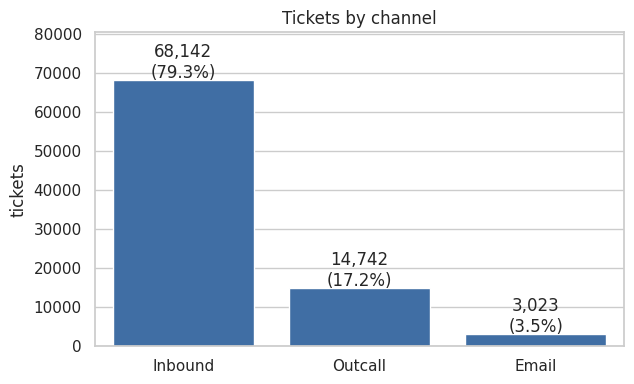

In [17]:
# Chart - 2 visualization code
s = eda["channel_name"].value_counts()
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.barplot(x=s.index, y=s.values, color=BLUE, ax=ax)
for i, v in enumerate(s.values): ax.text(i, v + 600, f"{v:,}\n({v / s.sum():.1%})", ha="center")
ax.set_ylim(0, s.max() * 1.18); ax.set_ylabel("tickets"); ax.set_xlabel("")
ax.set_title("Tickets by channel"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Channel has only three levels, so a simple labelled bar chart shows both absolute volume and share at a glance.

##### 2. What is/are the insight(s) found from the chart?

**Inbound calls dominate (79.3 %)**, outbound calls are 17.2 % and e-mail is only 3.5 % (3,023 tickets). Even the smallest channel has thousands of tickets, so channel comparisons later are statistically meaningful.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the load is concentrated on the phone channel, so improvements in call handling pay off at scale. **Negative:** because e-mail is so small it is easily ignored in operations - Chart 6 shows that is exactly where satisfaction is weakest, so a neglected small channel can quietly hurt the brand.

#### Chart - 3: Ticket volume by issue category  [Univariate]

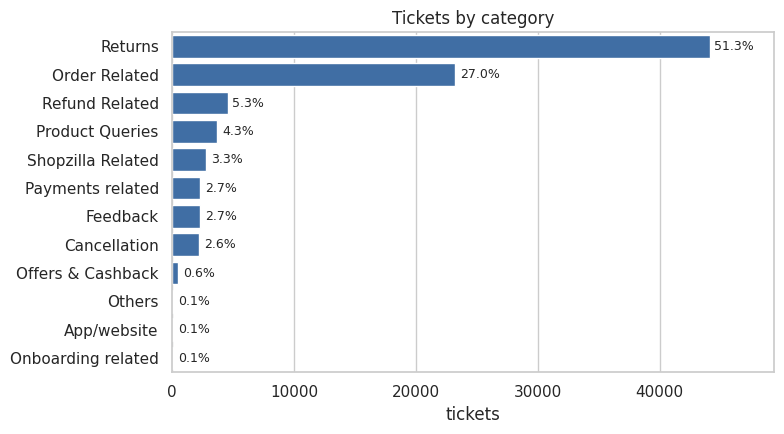

In [18]:
# Chart - 3 visualization code
s = eda["category"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=s.values, y=s.index, color=BLUE, ax=ax)
for i, v in enumerate(s.values): ax.text(v + 400, i, f"{v / s.sum():.1%}", va="center", fontsize=9)
ax.set_xlim(0, s.max() * 1.12); ax.set_xlabel("tickets"); ax.set_ylabel("")
ax.set_title("Tickets by category"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A sorted horizontal bar chart handles 12 long category names much better than a column chart or a pie and exposes the long tail immediately.

##### 2. What is/are the insight(s) found from the chart?

**Returns (51.3 %) and Order Related (27.0 %) account for ~78 % of all tickets.** Eight categories each have under 5 % of the volume and four (App/website, Onboarding, Others, Offers) have fewer than 500 tickets in the whole month.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a handful of categories drive the workload, so process fixes there (e.g. self-service returns tracking) reduce cost and wait times at scale. **Negative:** tiny categories have very noisy statistics - any 'insight' about them (e.g. the 33 % dissatisfaction in 'Others', n=99) must be read with caution, which is why later charts print the sample size and confidence intervals.

#### Chart - 4: Distribution of response time  [Univariate]

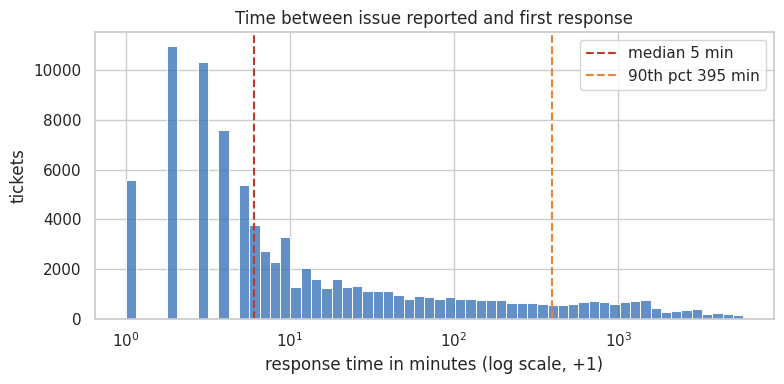

count    85907.0
mean       169.7
std        555.8
min          0.0
50%          5.0
75%         35.0
90%        395.0
95%       1079.0
99%       3007.0
max       5758.0
Name: response_min, dtype: float64


In [19]:
# Chart - 4 visualization code
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(eda["response_min"] + 1, log_scale=True, bins=60, color=BLUE, ax=ax)
med = eda["response_min"].median(); p90 = eda["response_min"].quantile(.9)
ax.axvline(med + 1, color=RED, ls="--", label=f"median {med:.0f} min")
ax.axvline(p90 + 1, color=ORANGE, ls="--", label=f"90th pct {p90:.0f} min")
ax.set_xlabel("response time in minutes (log scale, +1)"); ax.set_ylabel("tickets")
ax.set_title("Time between issue reported and first response"); ax.legend(); plt.tight_layout(); plt.show()
print(eda["response_min"].describe(percentiles=[.5, .75, .9, .95, .99]).round(1))

##### 1. Why did you pick the specific chart?

Response time spans four orders of magnitude (0 minutes to ~4 days), so a histogram on a **log axis** is needed to see the body and the tail of the distribution together; on a linear axis everything would collapse into one bar.

##### 2. What is/are the insight(s) found from the chart?

The distribution is extremely right-skewed: **median = 5 min**, but the 75th percentile is 35 min and the tail runs beyond 24 hours. There are two groups: a fast cluster of 0-10 minute responses (mostly calls) and a long tail of slow, probably e-mail or back-office resolved cases.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** most customers are answered fast, which supports the high CSAT. **Negative:** the long tail is where the unhappy customers live (see Charts 8 and 15). The skewness also tells us a **log transform is required** before feeding this variable to a neural network, otherwise a few extreme values dominate the gradient.

#### Chart - 5: Ticket volume by hour of day  [Univariate]

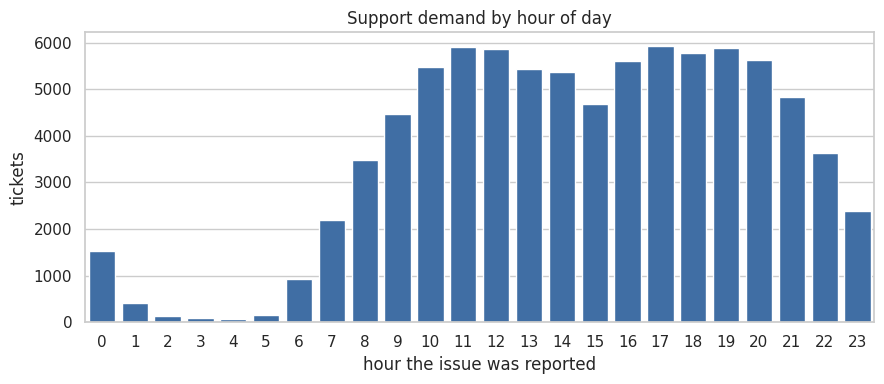

Share of tickets reported 09:00-21:59: 82.5%


In [20]:
# Chart - 5 visualization code
s = eda["rep_hour"].astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=s.index, y=s.values, color=BLUE, ax=ax)
ax.set_xlabel("hour the issue was reported"); ax.set_ylabel("tickets"); ax.set_title("Support demand by hour of day")
plt.tight_layout(); plt.show()
print("Share of tickets reported 09:00-21:59: {:.1%}".format(s.loc[9:21].sum() / s.sum()))

##### 1. Why did you pick the specific chart?

Hour of day is a cyclic, discrete variable; a bar chart per hour shows the daily demand profile and any gaps in coverage.

##### 2. What is/are the insight(s) found from the chart?

Demand is **business-hours driven**: it ramps up from 06:00, plateaus at roughly 4,700-5,900 tickets per hour between 10:00 and 21:00 and falls off after 22:00 (3,633 at 22:00, 2,398 at 23:00); between 01:00 and 05:00 there are fewer than 450 tickets per hour. About 82.5 % of tickets arrive between 09:00 and 21:59.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a predictable flat 10:00-21:00 plateau makes staffing easy to plan, and the near-empty night hours show night staffing can be minimal. **Negative:** the plateau is *flat*, not peaked - there is no obvious quiet period in which to schedule training, so coaching time has to be planned deliberately.

#### Chart - 6: CSAT mix by channel  [Bivariate: categorical vs categorical]

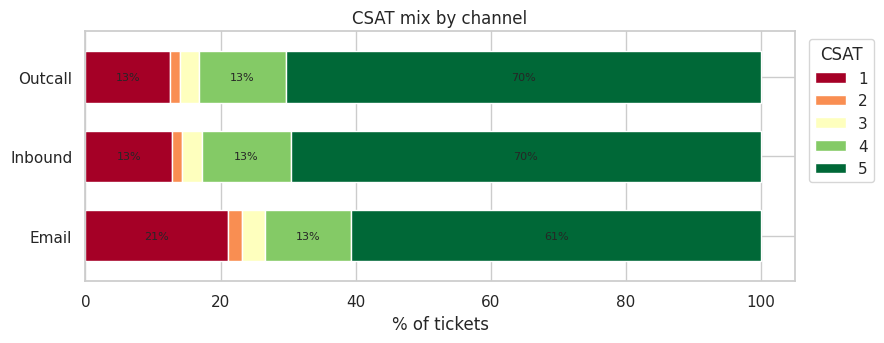

               mean   size
channel_name              
Email         3.899   3023
Inbound       4.251  68142
Outcall       4.270  14742
               rate      n     ci
channel_name                     
Outcall       0.140  14742  0.006
Inbound       0.143  68142  0.003
Email         0.232   3023  0.015


In [21]:
# Chart - 6 visualization code
ct = pd.crosstab(eda["channel_name"], eda["CSAT"], normalize="index") * 100
ct = ct.loc[["Email", "Inbound", "Outcall"]]
ax = ct.plot(kind="barh", stacked=True, figsize=(9, 3.6), colormap="RdYlGn", width=.65)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in c], label_type="center", fontsize=8)
ax.set_xlabel("% of tickets"); ax.set_ylabel(""); ax.set_title("CSAT mix by channel"); ax.legend(title="CSAT", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()
print(eda.groupby("channel_name")["CSAT"].agg(["mean", "size"]).round(3))
print(rate_table("channel_name").round(3))

##### 1. Why did you pick the specific chart?

A 100 % stacked bar shows the *whole* score mix per channel, which a single average would hide - important here because the target is polarised.

##### 2. What is/are the insight(s) found from the chart?

**E-mail is clearly worse: mean CSAT 3.90 versus 4.25 (Inbound) and 4.27 (Outcall), and 23.2 % of e-mail customers are dissatisfied versus ~14 % on the phone channels.** Inbound and Outcall are almost identical.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** there is a concrete, low-volume fix - improving e-mail response quality/time lifts a whole channel. Phone channels are performing consistently. **Negative:** e-mail's 23 % dissatisfaction is ~1.6x the phone rate; if the business pushes customers to e-mail to deflect call volume, overall satisfaction will fall.

#### Chart - 7: Dissatisfaction rate by issue category  [Bivariate]

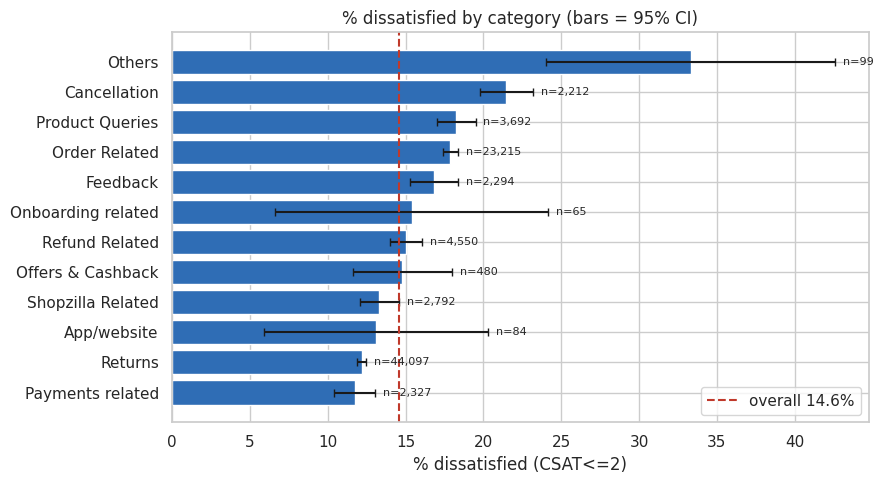

In [22]:
# Chart - 7 visualization code
g = rate_bar("category", horizontal=True, title="% dissatisfied by category (bars = 95% CI)", figsize=(9, 5))

##### 1. Why did you pick the specific chart?

A sorted horizontal bar of *rates* (not counts) with confidence intervals and sample sizes separates real differences from small-sample noise.

##### 2. What is/are the insight(s) found from the chart?

The worst categories are **Others (33 %, n=99), Cancellation (21.5 %, n=2,212), Product Queries (18.3 %) and Order Related (17.9 %)**; the best are **Payments (11.7 %) and Returns (12.2 %)**, even though Returns is the largest category. Only differences between large categories (Cancellation / Order / Product vs Returns / Payments) are statistically solid; 'Others', 'App/website' and 'Onboarding' have wide intervals.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the largest category (Returns, 51 % of volume) is also among the happiest - a good sign for the core process. Cancellation and Order Related are clear targets for training and process redesign. **Negative:** Order Related is large (23k tickets) *and* above average in dissatisfaction, so it contributes the biggest absolute number of unhappy customers; ignoring it would leave most of the problem untouched.

#### Chart - 8: Response-time bucket vs dissatisfaction  [Bivariate: numeric (binned) vs target]

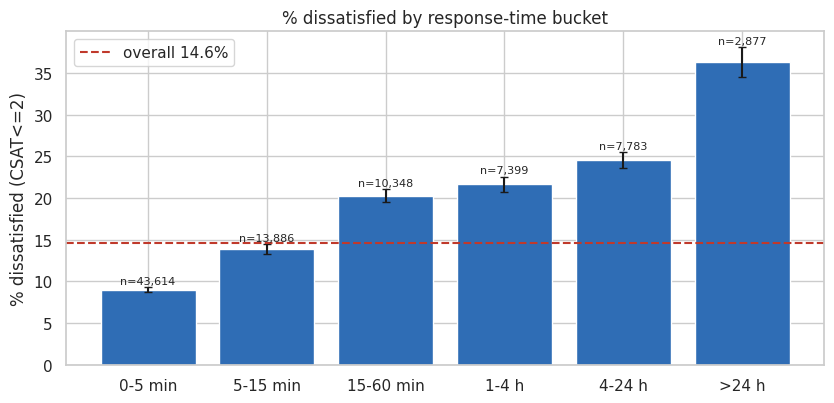

            rate      n     ci
rt_bucket                     
0-5 min    0.090  43614  0.003
5-15 min   0.139  13886  0.006
15-60 min  0.203  10348  0.008
1-4 h      0.216   7399  0.009
4-24 h     0.246   7783  0.010
>24 h      0.363   2877  0.018


In [23]:
# Chart - 8 visualization code
g = rate_bar("rt_bucket", order=["0-5 min", "5-15 min", "15-60 min", "1-4 h", "4-24 h", ">24 h"],
             title="% dissatisfied by response-time bucket", figsize=(8.5, 4.2))
print(g.round(3))

##### 1. Why did you pick the specific chart?

Binning the continuous response time into SLA-style buckets turns a skewed numeric variable into an easy-to-read dose-response chart, and error bars show the statistical certainty for each bucket.

##### 2. What is/are the insight(s) found from the chart?

A **monotonic dose-response**: dissatisfaction rises from **8.9 % (answered within 5 min) to 13.9 % (5-15 min), 20.3 % (15-60 min), 21.6 % (1-4 h), 24.6 % (4-24 h) and 36.3 % when the wait exceeds 24 hours.** Customers who wait over a day are 4x as likely to be unhappy as those answered within 5 minutes.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Strongly positive:** this is the clearest *actionable* lever in the dataset. A first-response SLA (e.g. 15 minutes) targets the point where the dissatisfaction curve starts to climb steeply. **Negative:** if slow tickets are not escalated, each extra hour in the queue costs satisfaction. The mild caveat is causality - complex issues are both slower and more upsetting - but the gradient is far too large to be ignored. This is the single most important feature for the ANN.

#### Chart - 9: Dissatisfaction by agent tenure  [Bivariate]

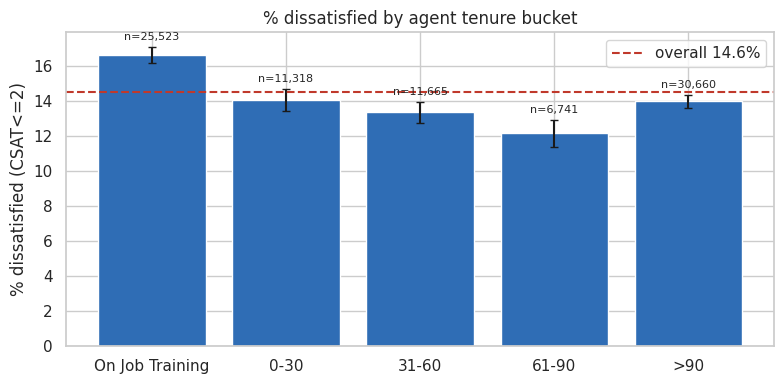

In [24]:
# Chart - 9 visualization code
g = rate_bar("Tenure Bucket", order=["On Job Training", "0-30", "31-60", "61-90", ">90"],
             title="% dissatisfied by agent tenure bucket", figsize=(8, 4))

##### 1. Why did you pick the specific chart?

Tenure is an ordered category, so I kept its natural order and used a rate bar with confidence intervals to see whether experience matters.

##### 2. What is/are the insight(s) found from the chart?

Agents **on job training have the highest dissatisfaction (16.6 %)**, while the 31-60 and 61-90 day cohorts are best (13.4 % and 12.2 %). Interestingly the >90-day group (14.0 %) is not better than the 0-30 day group (14.1 %), so the relationship is not simply 'more experience = better'.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the training cohort is a clear, targetable group - pairing trainees with mentors or routing hard categories (Cancellation, Order Related) away from them is cheap. **Negative:** the training cohort handles 25.5k tickets (30 % of all volume), so the 2-4 pt penalty adds up to hundreds of avoidable unhappy customers every month. The lack of improvement after 90 days suggests a plateau where ongoing coaching is missing.

#### Chart - 10: Dissatisfaction by agent shift  [Bivariate]

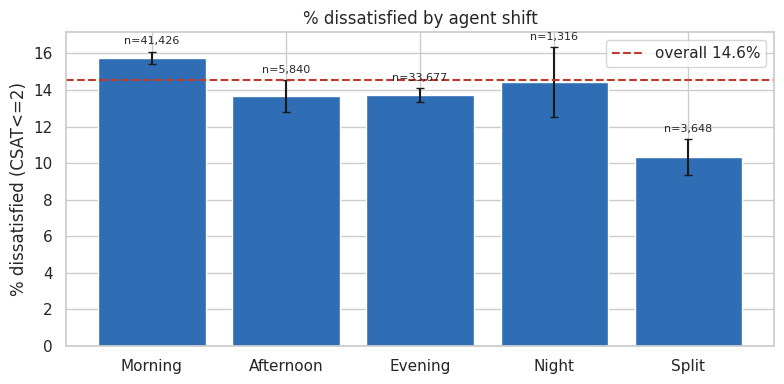

In [25]:
# Chart - 10 visualization code
g = rate_bar("Agent Shift", order=["Morning", "Afternoon", "Evening", "Night", "Split"],
             title="% dissatisfied by agent shift", figsize=(8, 4))

##### 1. Why did you pick the specific chart?

Same rate-bar design as Charts 7-9 so the effect sizes are directly comparable across variables.

##### 2. What is/are the insight(s) found from the chart?

**Morning shift is the weakest (15.8 %)** and the **Split shift the strongest (10.3 %)**; Afternoon, Evening and Night sit around 13.7-14.4 %. Morning handles the most tickets (41k), so its penalty is not a small-sample artefact.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the Split-shift practices (maybe different staffing mix or ticket types) could be studied and copied. **Negative:** Morning handles ~48 % of all tickets with the highest dissatisfaction, so it deserves attention in rostering (it likely also combines many trainee agents, a confounder worth testing in Chart 18).

#### Chart - 11: Dissatisfaction by product category  [Bivariate]

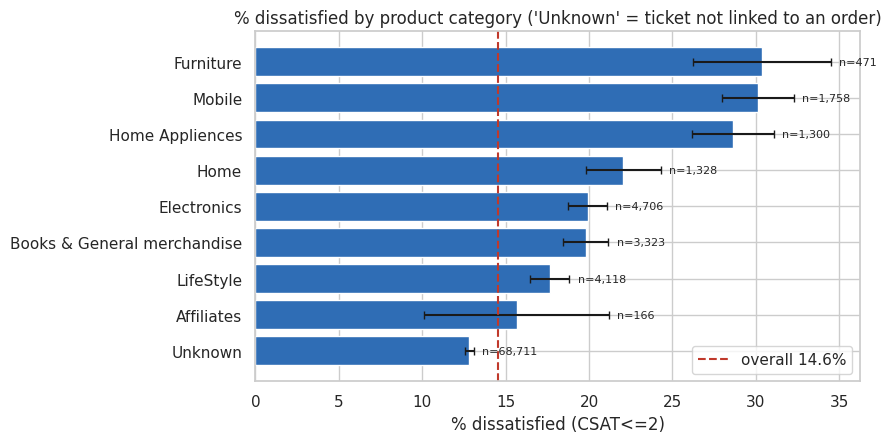

In [26]:
# Chart - 11 visualization code
g = rate_bar("Product_category", horizontal=True, min_n=100,
             title="% dissatisfied by product category ('Unknown' = ticket not linked to an order)", figsize=(9, 4.6))

##### 1. Why did you pick the specific chart?

Product category has nine levels with a very large 'Unknown' group; a rate bar with sample sizes makes comparison fair across very different volumes.

##### 2. What is/are the insight(s) found from the chart?

**Order-linked tickets are far less happy than non-order tickets: Unknown/no-order 12.8 % vs 21.5 % for order-linked tickets.** Within products, **Furniture (30 %), Mobile (30 %) and Home Appliances (29 %)** are the worst - all items that are bulky, expensive or need installation - whereas LifeStyle (17.7 %) and Books/General merchandise (19.8 %) are best.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the model gets a strong feature here (even *having* an order is predictive), and the business can create specialised handling (installation scheduling, damage-in-transit protocols) for Furniture/Mobile/Appliances. **Negative:** high-value categories are the ones with the most dissatisfaction; those customers likely spend more, so each lost customer costs more.

#### Chart - 12: Item price vs CSAT  [Bivariate: numeric vs categorical]

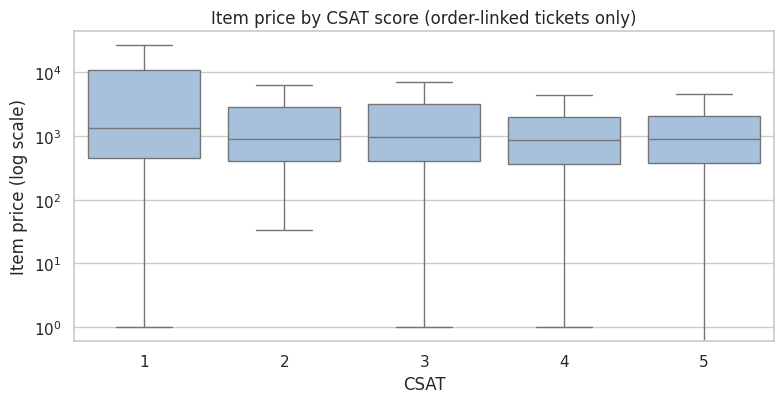

CSAT
1    1351.0
2     890.0
3     977.0
4     874.0
5     899.0
Name: Item_price, dtype: float64


In [27]:
# Chart - 12 visualization code
d = eda[raw["Item_price"].notna().values].copy()
d["Item_price"] = raw.loc[d.index, "Item_price"]
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.boxplot(data=d, x="CSAT", y="Item_price", color="#9ec1e6", showfliers=False, ax=ax)
ax.set_yscale("log"); ax.set_ylabel("Item price (log scale)"); ax.set_title("Item price by CSAT score (order-linked tickets only)")
plt.tight_layout(); plt.show()
print(d.groupby("CSAT")["Item_price"].median().round(0))

##### 1. Why did you pick the specific chart?

A box plot on a log axis is the standard way to compare a heavily skewed numeric variable (prices range from 0 to 165,000) across the five ordered score groups.

##### 2. What is/are the insight(s) found from the chart?

**Dissatisfied customers bought pricier items:** the median item price of 1-star tickets is 1,351 versus 874-977 for every other score, and the boxes for scores 2-5 overlap almost completely. So price matters mainly at the extreme: it is the 1-star group, not the 2-3 star group, that stands out.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a high-value-order flag (e.g. top price tier) is a cheap trigger for proactive outreach and priority routing, because those customers are both likelier to be angry and worth more. **Negative:** the relationship is not monotonic across 2-5, so price alone is a weak predictor; the model needs it combined with product category and response time. Treating price as a linear effect would be misleading.

#### Chart - 13: Daily trend of customer satisfaction  [Bivariate: time series]

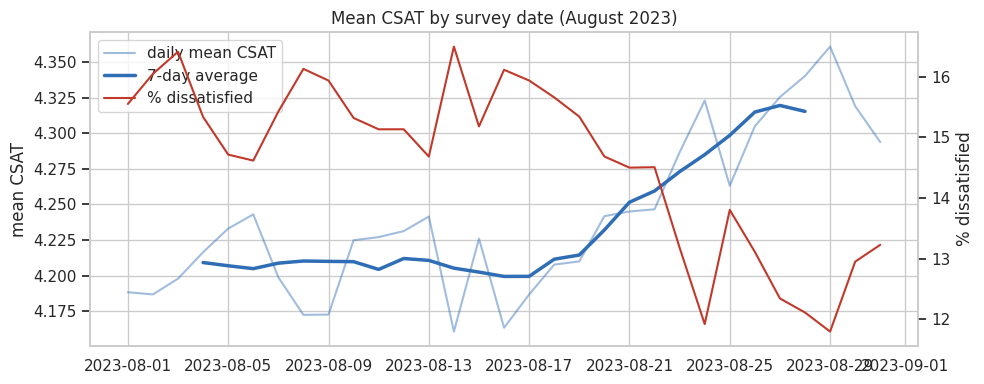

{'mean_csat': 4.209, 'low': 0.154} <- first week
{'mean_csat': 4.315, 'low': 0.128} <- last week


In [28]:
# Chart - 13 visualization code
daily = eda.groupby("survey_date").agg(mean_csat=("CSAT", "mean"), low=("low", "mean"), n=("CSAT", "size"))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily["mean_csat"], color=BLUE, alpha=.45, label="daily mean CSAT")
ax.plot(daily.index, daily["mean_csat"].rolling(7, center=True).mean(), color=BLUE, lw=2.5, label="7-day average")
ax.set_ylabel("mean CSAT"); ax.set_title("Mean CSAT by survey date (August 2023)")
ax2 = ax.twinx(); ax2.plot(daily.index, daily["low"] * 100, color=RED, lw=1.5, label="% dissatisfied"); ax2.set_ylabel("% dissatisfied"); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plt.show()
print(daily.iloc[:7][["mean_csat", "low"]].mean().round(3).to_dict(), "<- first week")
print(daily.iloc[-7:][["mean_csat", "low"]].mean().round(3).to_dict(), "<- last week")

##### 1. Why did you pick the specific chart?

A line chart is the natural choice for a time series, and the rolling average strips out day-to-day noise so the underlying trend is visible. Dissatisfaction is overlaid on a second axis.

##### 2. What is/are the insight(s) found from the chart?

Satisfaction **improves steadily across the month**: the first week averages ~4.21 with ~15.4 % dissatisfied, the last week ~4.32 with ~12.8 % dissatisfied; the step-up starts around 22-23 August. Within the month there is no weekly seasonality worth speaking of.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a real, sustained improvement - worth finding out what changed around 22 Aug (staffing, SLA, a policy) and keeping it. **Caution / negative for modelling:** the data show a time drift, so a randomly-split test set is slightly optimistic compared with predicting the *future*; with only one month of data a time-based split would leave too little training data, which is a stated limitation and the reason models should be retrained regularly in production.

#### Chart - 14: Dissatisfaction by manager  [Bivariate]

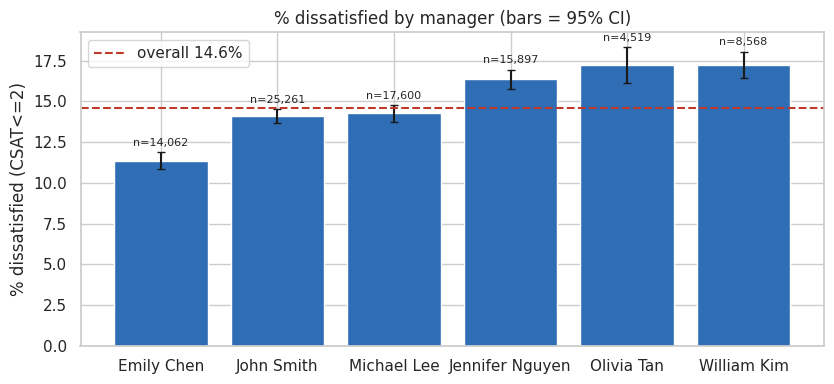

In [29]:
# Chart - 14 visualization code
g = rate_bar("Manager", title="% dissatisfied by manager (bars = 95% CI)", figsize=(8.5, 4))

##### 1. Why did you pick the specific chart?

Only six managers exist, so a rate bar with confidence intervals is enough to see whether team-level differences are real.

##### 2. What is/are the insight(s) found from the chart?

Dissatisfaction ranges from **11.3 % (Emily Chen) to 17.2 % (William Kim, Olivia Tan)** - a 6-point spread, and the confidence intervals do not overlap between the extremes. Teams under John Smith and Michael Lee sit at the overall average (~14 %).

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** best-practice sharing - what does Emily Chen's team do differently? **Negative / caution:** this is a *team-level* comparison; teams handle different category/product mixes, so before using it for performance reviews it must be adjusted for ticket mix (the model's agent/manager features do implicitly). Using raw rankings for evaluation could be unfair.

#### Chart - 15: Do agents really differ? Observed spread vs pure chance  [Bivariate / Univariate]

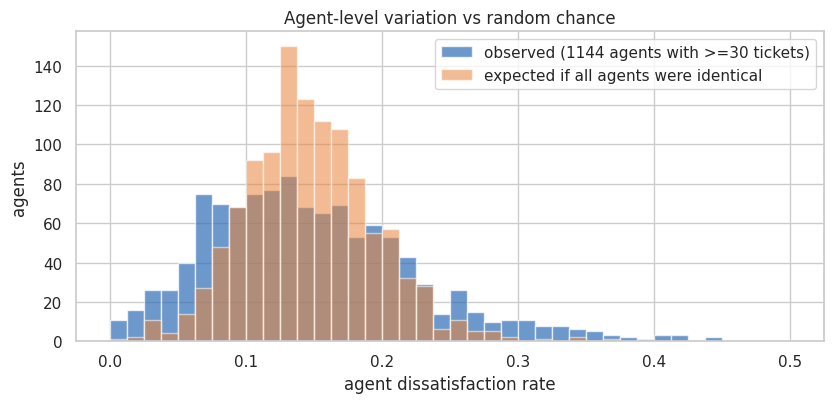

std observed = 0.088  vs  std expected by chance = 0.047


In [30]:
# Chart - 15 visualization code
ag = eda.groupby(raw["Agent_name"]).agg(n=("low", "size"), rate=("low", "mean"))
ag = ag[ag.n >= 30]
rng = np.random.default_rng(SEED)
simulated = rng.binomial(ag["n"].values, GLOBAL_LOW) / ag["n"].values      # what we'd see if all agents were identical
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bins = np.linspace(0, .5, 41)
ax.hist(ag["rate"], bins=bins, alpha=.7, color=BLUE, label=f"observed ({len(ag)} agents with >=30 tickets)")
ax.hist(simulated, bins=bins, alpha=.55, color=ORANGE, label="expected if all agents were identical")
ax.set_xlabel("agent dissatisfaction rate"); ax.set_ylabel("agents"); ax.set_title("Agent-level variation vs random chance")
ax.legend(); plt.tight_layout(); plt.show()
print(f"std observed = {ag['rate'].std():.3f}  vs  std expected by chance = {simulated.std():.3f}")

##### 1. Why did you pick the specific chart?

With 1,371 agents (too many to plot individually) the question is whether agent identity carries real signal. Overlaying the observed histogram on a simulation of 'all agents are identical' answers that directly and is a built-in significance check.

##### 2. What is/are the insight(s) found from the chart?

The observed distribution is **clearly wider than chance alone would produce**: standard deviation ~8.8 percentage points vs ~4.7 expected by chance (the printed output confirms both). Some agents have dissatisfaction rates above 30 % and others near 0 %, which cannot be explained by sampling noise.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** agent identity is a genuine predictor, which justifies engineering an agent-level feature (smoothed, out-of-fold target encoding in `csat_utils.AgentStats`) rather than ignoring the column. Operationally, coaching the high-dissatisfaction tail would shift the whole distribution. **Negative:** the same feature makes the model less useful for brand-new agents (cold start) - for them the encoder falls back to the global average.

#### Chart - 16: Channel x category dissatisfaction heat-map  [Multivariate]

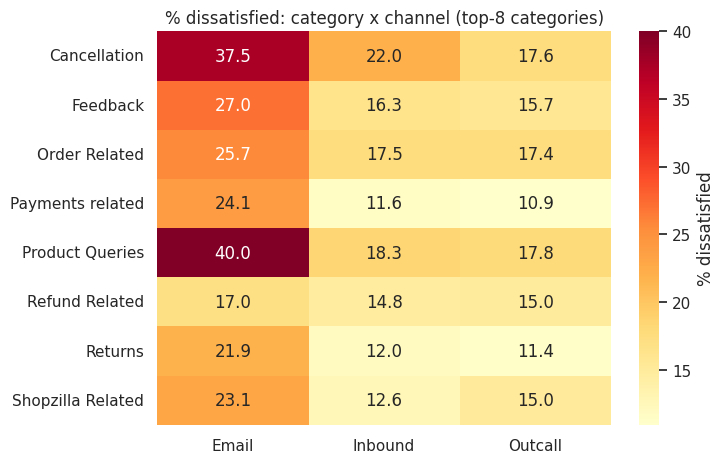

Smallest cell size: 10


In [31]:
# Chart - 16 visualization code
top = eda["category"].value_counts().index[:8]
d = eda[eda["category"].isin(top)]
pv = d.pivot_table(index="category", columns="channel_name", values="low", aggfunc="mean") * 100
cnt = d.pivot_table(index="category", columns="channel_name", values="low", aggfunc="size")
fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.heatmap(pv, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "% dissatisfied"}, ax=ax)
ax.set_title("% dissatisfied: category x channel (top-8 categories)"); ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); plt.show()
print("Smallest cell size:", int(cnt.min().min()))

##### 1. Why did you pick the specific chart?

A heat-map handles a two-dimensional categorical interaction (8 x 3 = 24 cells) in one picture and highlights hot spots with colour.

##### 2. What is/are the insight(s) found from the chart?

The e-mail penalty is **not uniform**. The most reliable cell is **Returns by e-mail: 21.9 % dissatisfied (n=1,213) vs 11-12 % by phone**; Payments shows 24 % by e-mail vs ~11 % by phone, and Order Related 25.7 % vs ~17.5 %. Cancellation by e-mail looks worst (37.5 %) but that cell has only 64 tickets, so treat it as a warning sign rather than a fact. Interestingly, Outcall beats Inbound for Cancellation (17.6 % vs 22.0 %), while Offers & Cashback is the reverse (23.3 % Outcall vs 13.6 % Inbound, small n).

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it points to specific combinations to fix (e-mail returns and payments handling; inbound cancellation scripts) instead of blanket changes. **Negative / modelling implication:** the effect of channel depends on category, i.e. there is an **interaction** - in principle a neural network can capture such interactions where a linear model needs hand-crafted terms - although Section 7 will show that, in this dataset, the practical gain over logistic regression turns out to be negligible.

#### Chart - 17: Correlation heat-map of engineered numeric features  [Multivariate]

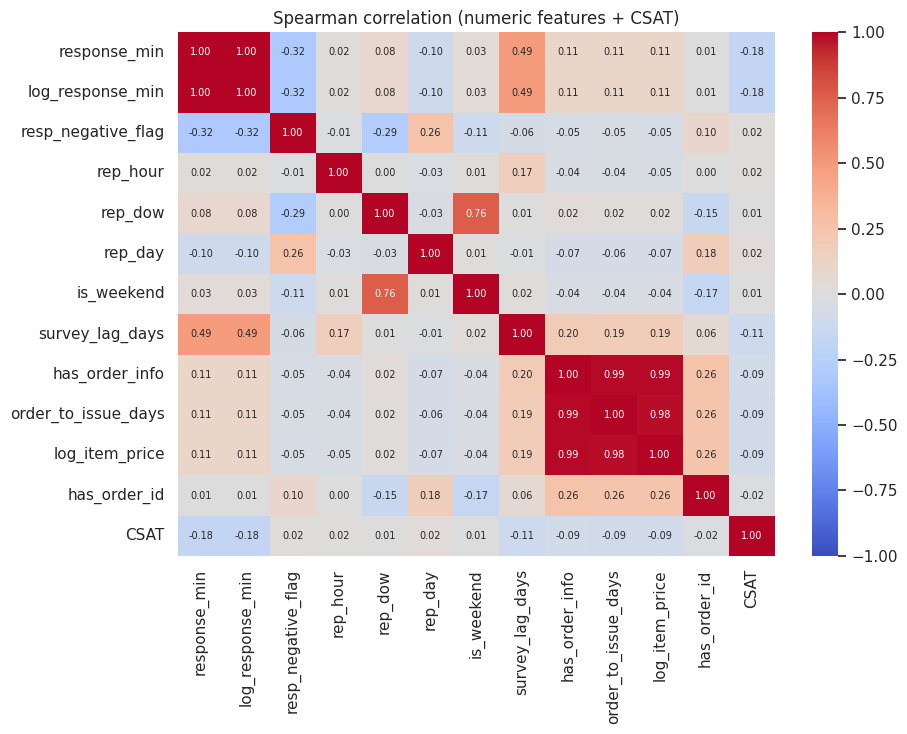

response_min          -0.178
log_response_min      -0.178
survey_lag_days       -0.112
log_item_price        -0.091
order_to_issue_days   -0.089
has_order_info        -0.086
has_order_id          -0.021
is_weekend             0.007
rep_dow                0.007
rep_hour               0.015
resp_negative_flag     0.016
rep_day                0.024
Name: CSAT, dtype: float64


In [32]:
# Chart - 17 visualization code
num = feat[NUM_COLS].copy(); num["CSAT"] = y
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation (numeric features + CSAT)")
plt.tight_layout(); plt.show()
print(corr["CSAT"].drop("CSAT").sort_values().round(3))

##### 1. Why did you pick the specific chart?

A correlation matrix is the standard multivariate check for multicollinearity and for a first ranking of numeric predictors. Spearman is used because the response time and price are skewed and the target is ordinal.

##### 2. What is/are the insight(s) found from the chart?

All correlations with CSAT are small: **response time is the strongest (Spearman -0.18)**, followed by survey lag (-0.11), item price (-0.09), order-to-issue days (-0.09) and the has-order flag (-0.09). Calendar features (hour, weekday, weekend, day-of-month) are essentially zero (|rho| < 0.03). The response-time pair (raw and log) are identical in rank terms, as expected, and survey lag / order flags correlate with each other, so the numeric block has some redundancy but nothing extreme.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it confirms what the earlier charts suggested: response time is the number-one operational lever, and a longer wait before the survey goes with lower scores (customers whose issue dragged on rate lower). **Negative / modelling implication:** no single numeric feature explains more than ~3% of the rank variance (rho^2), so a linear model on these will be weak; whatever predictive power exists comes from combining them with categorical context. Calendar features carry almost no signal and are kept only because they are harmless. Spearman measures monotonic association only, so it can miss the non-linear effects the ANN can learn.

#### Chart - 18: Agent shift x tenure dissatisfaction heat-map  [Multivariate]

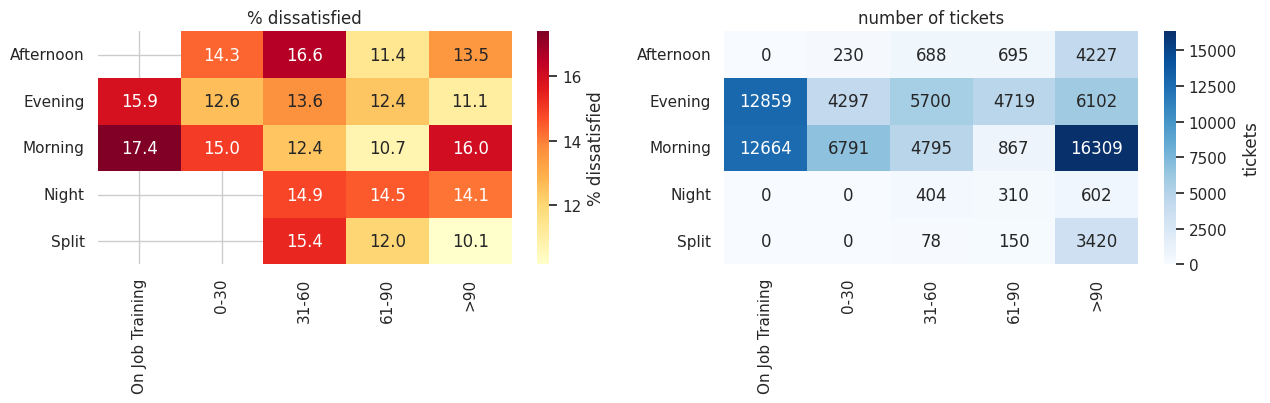

In [33]:
# Chart - 18 visualization code
pv = eda.pivot_table(index="Agent Shift", columns="Tenure Bucket", values="low", aggfunc="mean")[["On Job Training", "0-30", "31-60", "61-90", ">90"]] * 100
cnt = eda.pivot_table(index="Agent Shift", columns="Tenure Bucket", values="low", aggfunc="size")[["On Job Training", "0-30", "31-60", "61-90", ">90"]].fillna(0).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.heatmap(pv, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "% dissatisfied"}); axes[0].set_title("% dissatisfied")
sns.heatmap(cnt, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar_kws={"label": "tickets"}); axes[1].set_title("number of tickets")
for a in axes: a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Charts 9 and 10 each looked at one agent attribute; a paired heat-map (rate + sample size) tests whether the shift effect is really a tenure effect in disguise (a confounder) and shows which cells are too small to trust.

##### 2. What is/are the insight(s) found from the chart?

On-job-training agents exist **only in the Morning and Evening shifts** (about 12.7k and 12.9k tickets). Within Morning, even experienced agents (>90 days) have a high 16.0 % dissatisfaction, versus 11.1 % for experienced Evening agents, so Morning's weakness is **not** just a tenure effect. The Split shift's 10.1 % is partly composition: 94 % of its tickets are handled by >90-day agents. The cells with the worst rates are Morning/OJT (17.4 %) and Morning/>90 (16.0 %).

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it shows where to act - Morning-shift quality (regardless of tenure) and trainees in both shifts - rather than a blanket 'train everyone'. Some cells are empty or tiny (Night has no trainees, Split only 78 31-60 day tickets), so only large cells should drive decisions. **Negative / modelling implication:** shift, tenure and agent identity overlap strongly (confounding), so a single feature should not be read in isolation; this is another reason to let the ANN learn them jointly and to explain it with grouped permutation importance.

### Summary of the EDA

| Driver | Strength | Evidence |
|---|---|---|
| **Response time** | Very strong | 8.9 % -> 36.3 % dissatisfied from <5 min to >24 h |
| **Order-linked / product category** | Strong | 12.8 % (no order) vs 21.5 %; Furniture/Mobile/Appliances ~30 % |
| **Channel (e-mail)** | Strong, small volume | 23.2 % vs ~14 % |
| **Issue category** | Moderate | Cancellation 21.5 % vs Payments 11.7 % |
| **Agent / manager / tenure / shift** | Moderate | Agent spread 2x wider than chance; OJT 16.6 % |
| **Time of day / weekday** | Weak | Flat 14-15 % across weekdays and most hours |

The dependence is mostly **non-linear and interaction-heavy** (channel x category, tenure x shift), and a large part of dissatisfaction is simply *not predictable from the ticket's metadata* (e.g. product quality, delivery). We therefore expect a **moderate ceiling** on predictive power - important for setting honest expectations.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Three statements are tested at a significance level of **alpha = 0.05**: (1) slow responses raise dissatisfaction, (2) the channel matters, (3) agents still in training deliver lower satisfaction.

### Hypothetical Statement - 1: Tickets answered after more than 60 minutes have a higher dissatisfaction rate than tickets answered within 60 minutes.

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** p_slow <= p_fast (the proportion with CSAT <= 2 is no higher for slow responses).
* **H1:** p_slow > p_fast (one-sided).

#### 2. Perform an appropriate statistical test.

In [34]:
# Perform Statistical Test to obtain P-Value  -  H1: two-proportion z-test (one-sided)
slow = eda.loc[eda.response_min > 60, "low"]; fast = eda.loc[eda.response_min <= 60, "low"]
p1, p2, n1, n2 = slow.mean(), fast.mean(), len(slow), len(fast)
p_pool = (slow.sum() + fast.sum()) / (n1 + n2)
z = (p1 - p2) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
p_val = 1 - stats.norm.cdf(z)
print(f"slow (>60 min): {p1:.3%} (n={n1:,}) | fast (<=60 min): {p2:.3%} (n={n2:,})")
print(f"z = {z:.2f} | one-sided p-value = {p_val:.3e}")
print("Reject H0" if p_val < 0.05 else "Fail to reject H0")

slow (>60 min): 25.234% (n=18,059) | fast (<=60 min): 11.726% (n=67,848)
z = 45.73 | one-sided p-value = 0.000e+00
Reject H0


##### Which statistical test have you done to obtain P-Value?

A **one-sided two-proportion z-test**.

##### Why did you choose the specific statistical test?

The outcome (dissatisfied yes/no) is binary and the two groups are independent and very large (n > 18,000 each), so the normal approximation of the difference of two proportions is valid. The hypothesis is directional (slow -> *more* dissatisfaction), so a one-sided test is appropriate. **Conclusion:** the p-value is effectively zero, so we **reject H0** - slow responses are associated with significantly higher dissatisfaction (about 25 % vs 12 %).

### Hypothetical Statement - 2: The dissatisfaction rate depends on the support channel.

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** Dissatisfaction (CSAT <= 2) is independent of channel.
* **H1:** Dissatisfaction is associated with channel.

#### 2. Perform an appropriate statistical test.

In [35]:
# Perform Statistical Test to obtain P-Value  -  H2: chi-square test of independence
ct = pd.crosstab(eda["channel_name"], eda["low"])
chi2, p_val, dof, expected = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(ct.assign(rate=lambda d: (d[1] / (d[0] + d[1])).round(3)))
print(f"chi2 = {chi2:.1f}, dof = {dof}, p-value = {p_val:.3e}, Cramer's V = {cramers_v:.3f}")
print("Reject H0" if p_val < 0.05 else "Fail to reject H0")

low               0     1   rate
channel_name                    
Email          2323   700  0.232
Inbound       58386  9756  0.143
Outcall       12685  2057  0.140
chi2 = 187.1, dof = 2, p-value = 2.378e-41, Cramer's V = 0.047
Reject H0


##### Which statistical test have you done to obtain P-Value?

**Chi-square test of independence** (plus Cramer's V as an effect size).

##### Why did you choose the specific statistical test?

Both variables are categorical (three channels x dissatisfied yes/no) and all expected cell counts are far above 5. **Conclusion:** p is far below 0.05, so we **reject H0** - channel and dissatisfaction are associated. Note the *effect size* (Cramer's V is small, ~0.05): the effect is statistically certain but driven almost entirely by e-mail, which is only 3.5 % of volume. Statistical significance with n = 86k is easy to obtain, which is why we also report the effect size.

### Hypothetical Statement - 3: Agents on job training receive lower CSAT scores than fully trained agents.

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** The CSAT score distribution of On-Job-Training agents is the same as (or higher than) that of other agents.
* **H1:** OJT agents' CSAT scores are stochastically lower (one-sided).

#### 2. Perform an appropriate statistical test.

In [36]:
# Perform Statistical Test to obtain P-Value  -  H3: Mann-Whitney U test (one-sided)
ojt = eda.loc[eda["Tenure Bucket"] == "On Job Training", "CSAT"]
rest = eda.loc[eda["Tenure Bucket"] != "On Job Training", "CSAT"]
u, p_val = stats.mannwhitneyu(ojt, rest, alternative="less")
print(f"mean CSAT  OJT: {ojt.mean():.3f} (n={len(ojt):,}) | others: {rest.mean():.3f} (n={len(rest):,})")
print(f"U = {u:.0f}, one-sided p-value = {p_val:.3e}")
print("Reject H0" if p_val < 0.05 else "Fail to reject H0")

mean CSAT  OJT: 4.145 (n=25,523) | others: 4.283 (n=60,384)
U = 732169132, one-sided p-value = 3.252e-46
Reject H0


##### Which statistical test have you done to obtain P-Value?

**Mann-Whitney U test** (one-sided, "less").

##### Why did you choose the specific statistical test?

CSAT is an **ordinal, strongly non-normal** variable (69 % are 5s), so a t-test's normality assumption is violated; the rank-based Mann-Whitney U test compares the two score distributions without assuming normality. **Conclusion:** p < 0.05, so we **reject H0** - trainees do score lower (mean 4.15 vs ~4.28), a small but real gap. Because trainees are 30 % of volume, even a small gap matters operationally.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [37]:
# Handling Missing Values & Missing Value Imputation
before = raw.isna().sum()
after = feat.isna().sum()
cmp_ = pd.DataFrame({"raw_missing": before.reindex(["Order_id", "order_date_time", "Customer_City", "Product_category", "Item_price", "connected_handling_time"]),
                     "after_engineering": 0})
print(cmp_)
print("\nTotal missing values left in the engineered feature frame:", int(feat.isna().sum().sum()))

                         raw_missing  after_engineering
Order_id                       18232                  0
order_date_time                68693                  0
Customer_City                  68828                  0
Product_category               68711                  0
Item_price                     68701                  0
connected_handling_time        85665                  0



Total missing values left in the engineered feature frame: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

* **Structural missingness -> explicit flag + neutral fill.** The ~80 % missing in order date, price, city and product category means "this ticket is not about an order". Deleting rows or mean-imputing would destroy/blur this. We use `has_order_info` / `has_order_id` flags, fill the numerics with 0 and the categoricals with a real `Unknown` level, so the model can learn *"missing" has a meaning* (Chart 11 proves it does: 12.8 % vs ~22 % dissatisfaction).
* **Impossible timestamps:** negative response times are clipped to 0 and flagged (`resp_negative_flag`).
* **Safety net:** each preprocessing pipeline also contains a median `SimpleImputer`, so a future ticket with an unparsable timestamp will not crash scoring.
* **Dropped, not imputed:** `connected_handling_time` (99.7 % missing - any imputation would be fabrication).

### 2. Handling Outliers

              skew_raw  skew_after_log1p       p99       max
response_min      5.32              1.06   3007.00    5758.0
Item_price        4.23              0.52  62998.55  164999.0


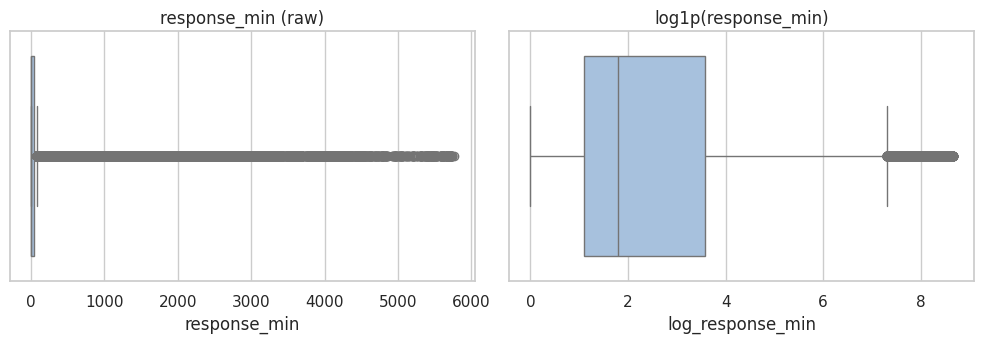

In [38]:
# Handling Outliers
from scipy.stats import skew
price = pd.to_numeric(raw["Item_price"], errors="coerce").dropna()
out = pd.DataFrame({
    "skew_raw": [skew(feat["response_min"]), skew(price)],
    "skew_after_log1p": [skew(feat["log_response_min"]), skew(np.log1p(price))],
    "p99": [feat["response_min"].quantile(.99), price.quantile(.99)],
    "max": [feat["response_min"].max(), price.max()]}, index=["response_min", "Item_price"]).round(2)
print(out)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sns.boxplot(x=feat["response_min"], ax=axes[0], color="#9ec1e6"); axes[0].set_title("response_min (raw)")
sns.boxplot(x=feat["log_response_min"], ax=axes[1], color="#9ec1e6"); axes[1].set_title("log1p(response_min)")
plt.tight_layout(); plt.show()

#### What all outlier treatment techniques have you used and why did you use those techniques?

The "outliers" are **real, informative events** - a response taking 3 days is exactly the case that produces an angry customer (36 % dissatisfied). Deleting or winsorising them would remove the signal we want to learn. Instead we **log1p-transform** response time and item price, which cuts skewness drastically and stops a few extreme values from dominating the neural network's gradients, and we then standardise. The only value *corrected* is the physically impossible negative response time (clipped at 0 and flagged), and `order_to_issue_days` is clipped at 400 days to bound data-entry errors.

### 3. Categorical Encoding

In [39]:
# Categorical Encoding - cardinalities decide the encoding strategy
card = pd.DataFrame({"n_levels": feat[CAT_COLS + [AGENT_COL]].nunique()})
card["encoding_used"] = ["one-hot (dense models) / learned embedding (Model 3)"] * len(CAT_COLS) + ["smoothed out-of-fold target statistics"]
card

,n_levels,encoding_used
channel_name,3,one-hot (dense models) / learned embedding (Mo...
category,12,one-hot (dense models) / learned embedding (Mo...
Sub-category,57,one-hot (dense models) / learned embedding (Mo...
Product_category,10,one-hot (dense models) / learned embedding (Mo...
Tenure Bucket,5,one-hot (dense models) / learned embedding (Mo...
Agent Shift,5,one-hot (dense models) / learned embedding (Mo...
Manager,6,one-hot (dense models) / learned embedding (Mo...
Supervisor,40,one-hot (dense models) / learned embedding (Mo...
Customer_City,1783,one-hot (dense models) / learned embedding (Mo...
Agent_name,1371,smoothed out-of-fold target statistics


#### What all categorical encoding techniques have you used & why did you use those techniques?

* **Low-cardinality variables (channel, category, tenure, shift, manager, product):** one-hot encoding for the logistic regression and the dense ANN (no artificial order is imposed on nominal data).
* **Long-tailed variables (Sub-category 57 levels, Customer_City 1,782 levels, Supervisor 40):** one-hot with `min_frequency=100` - every level with fewer than 100 tickets is pooled into an automatic "infrequent" bucket, which prevents hundreds of near-empty columns and handles never-seen levels at serving time (`handle_unknown="infrequent_if_exist"`).
* **Model 3 (embedding ANN):** the same variables are integer-coded and fed through a **learned embedding layer**, so the network discovers its own dense representation (e.g. that "Cancellation" and "Product Queries" behave similarly) - the standard technique for categorical data in deep learning.
* **Agent_name (1,371 levels):** one-hot would create ~1,400 sparse columns. Instead we use a **smoothed target encoding** (agent's historical dissatisfaction rate, mean CSAT and ticket volume, shrunk towards the global mean with m=20 pseudo-observations). It is computed **out-of-fold on the training data** so a ticket never sees its own label (no leakage), and unseen agents fall back to the global prior.

### 4. Textual Data Preprocessing 
(The production model deliberately does **not** use free text; this section builds a light-weight text pipeline used only in the labelled "upper-bound" experiment in Model 3.)

**Why are `Customer Remarks` excluded from the production model?** They are typed by the customer *in the same survey step as the score* ("Very bad", "Excellent service"). At the time we want to predict - while the ticket is still open - this text does not exist. Including it would give impressive but meaningless accuracy (**target leakage**). We still quantify what it would add, so the business understands the gap between "predictable from operations" and "known only after the survey".

In [40]:
# Textual preprocessing pipeline for Customer Remarks (used only in the upper-bound experiment)
import re
CONTRACTIONS = {"won't": "will not", "can't": "cannot", "n't": " not", "'re": " are", "'ve": " have", "'ll": " will", "'m": " am", "'s": " is"}
POS = {"good", "nice", "great", "excellent", "thanks", "thank", "best", "happy", "satisfied", "helpful", "awesome", "super", "perfect",
       "fine", "resolved", "quick", "fast", "polite", "wonderful", "amazing", "love", "superb", "outstanding", "prompt", "well", "ok", "okay"}
NEG = {"bad", "worst", "poor", "not", "no", "never", "waste", "pathetic", "disappointed", "horrible", "worse", "delay", "delayed", "late",
       "useless", "cheat", "fraud", "rude", "unsatisfied", "dissatisfied", "slow", "terrible", "irritating", "problem", "issue", "complaint",
       "waiting", "worthless", "unhappy", "nothing", "disgusting"}

def clean_remark(t: str) -> list:
    t = str(t).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)                         # remove URLs
    for k, v in CONTRACTIONS.items(): t = t.replace(k, v)            # expand contractions
    t = re.sub(r"[^a-z\s]", " ", t)                                  # drop punctuation, digits, emojis
    return t.split()                                                 # whitespace tokenisation (lower-cased, no stop-word removal: 'not', 'no' matter)

def remark_features(series: pd.Series) -> pd.DataFrame:
    toks = series.fillna("").map(clean_remark)
    pos = toks.map(lambda w: sum(x in POS for x in w)); neg = toks.map(lambda w: sum(x in NEG for x in w))
    return pd.DataFrame({"has_remark": series.notna().astype(int), "remark_len": toks.map(len),
                         "pos_hits": pos, "neg_hits": neg, "remark_sentiment": pos - neg}, index=series.index)

rem = remark_features(raw["Customer Remarks"])
print(pd.concat([raw["Customer Remarks"], rem], axis=1).dropna(subset=["Customer Remarks"]).head(6))
print("\nMean CSAT by remark sentiment (only tickets with a remark):")
print(pd.concat([rem.remark_sentiment.clip(-2, 2), pd.Series(y, index=rem.index, name="CSAT")], axis=1)[rem.has_remark == 1].groupby("remark_sentiment").CSAT.agg(["mean", "size"]).round(2))

                                     Customer Remarks  has_remark  remark_len  \
7                                           Very good           1           2   
8   Shopzilla app and it's all coustomer care serv...           1          16   
11                                           Very bad           1           2   
17                                         Something            1           1   
19                                           All good           1           2   
21                                              Good            1           1   

    pos_hits  neg_hits  remark_sentiment  
7          1         0                 1  
8          1         0                 1  
11         0         1                -1  
17         0         0                 0  
19         1         0                 1  
21         1         0                 1  

Mean CSAT by remark sentiment (only tickets with a remark):
                  mean   size
remark_sentiment             
-2        

#### Text normalisation, tokenisation, POS tagging & vectorisation - which did you use and why?

* **Expand contractions, lower-casing, removing punctuation/URLs/digits** - implemented in `clean_remark`.
* **Stop-words were intentionally *not* removed**: in sentiment words like *not*, *no*, *never* are the signal ("not good").
* **Tokenisation:** simple whitespace tokens - the remarks are very short (median 1-2 words, many Hinglish) so a heavy tokenizer adds nothing.
* **Stemming/lemmatisation and POS tagging were skipped:** the vocabulary is tiny and noisy (spelling variants and Hindi-English mixes), where a lexicon with spelling variants works better than linguistic normalisation.
* **Vectorisation:** a **sentiment-lexicon score** (positive hits - negative hits) plus `has_remark` and length. With 67 % of remarks missing and the text unusable for real-time prediction anyway, a 5-number lexicon representation is the proportionate choice compared with TF-IDF or an LSTM.

### 5. Feature Manipulation & Selection

#### 1. Feature Manipulation

The features created (all in `csat_utils.engineer`): **response_min / log_response_min / resp_negative_flag**, **rep_hour, rep_dow, rep_day, is_weekend, survey_lag_days**, **has_order_info, order_to_issue_days, log_item_price, has_order_id**, plus the **agent-level target statistics** (agent_low_rate, agent_mean_csat, agent_volume). The ANN is free to create its own interactions (e.g. channel x category); we deliberately did *not* hand-code them.

#### 2. Feature Selection

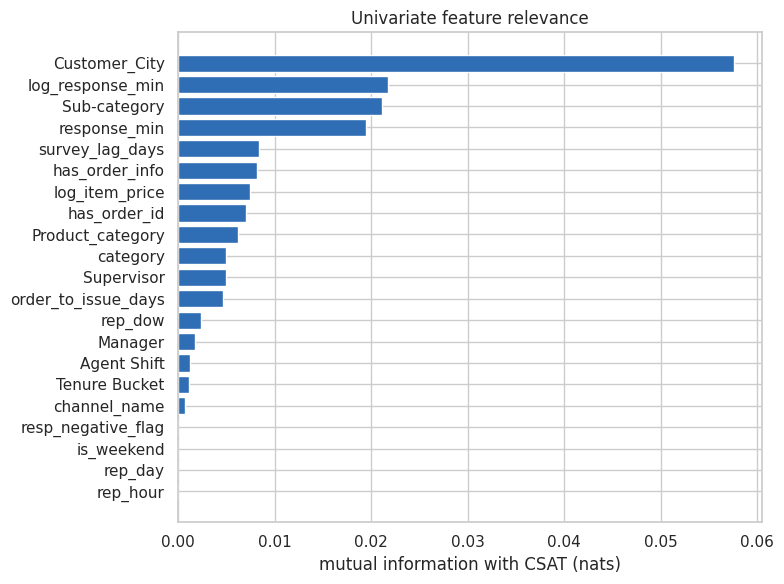

Customer_City       0.0576
log_response_min    0.0218
Sub-category        0.0211
response_min        0.0194
survey_lag_days     0.0084
has_order_info      0.0082
log_item_price      0.0075
has_order_id        0.0070
Product_category    0.0062
category            0.0049
dtype: float64


In [41]:
# Feature selection: mutual information between each feature and CSAT (30k-row sample for speed)
Xmi = feat[CAT_COLS + NUM_COLS].copy()
for c in CAT_COLS: Xmi[c] = pd.factorize(Xmi[c])[0]
idx = np.random.default_rng(SEED).choice(len(Xmi), 30000, replace=False)
mi = mutual_info_classif(Xmi.iloc[idx], y[idx], discrete_features=[c in CAT_COLS for c in Xmi.columns], random_state=SEED)
mi = pd.Series(mi, index=Xmi.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(mi.index, mi.values, color=BLUE); ax.set_xlabel("mutual information with CSAT (nats)"); ax.set_title("Univariate feature relevance")
plt.tight_layout(); plt.show()
print(mi.sort_values(ascending=False).round(4).head(10))

##### What all feature selection methods have you used and why?

1. **Domain/leakage filter:** removed identifiers, the 99.7 %-missing handling time and the leaky remarks.
2. **Mutual information** (above): non-parametric, so it captures non-linear and categorical dependence, unlike Pearson correlation. It ranks the response-time features, sub-category and the order context among the useful ones, and calendar features low. **Caution:** it also puts `Customer_City` (1,783 levels, mostly 'Unknown') at the very top - a known bias of mutual information towards high-cardinality variables (a city almost 'memorises' tickets), which permutation importance later shows is spurious (City has no measurable importance). That is exactly why a second, model-based check is used.
3. **Model-based check:** after training, **permutation importance** (Section 7) validates that the retained features really carry signal.

##### Which all features you found important and why?

Response time (log) and the order-context group are the strongest; category, channel, sub-category, tenure and agent statistics give moderate lift. Calendar variables (hour, weekday, day-of-month, weekend) are individually weak (Chart 5/17) - but we **keep them**: a neural network with dropout and early stopping is robust to a few weak inputs, they cost nothing at inference, and removal would only be justified if permutation importance showed they hurt.

### 6. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes. **log1p** on response time and item price (skewness reduction, see the table in Outliers) and **cyclic information is kept simple** (hour and weekday as numbers) because their effects are weak. Categorical variables are one-hot / embedding encoded and agent identity target-encoded (Section 3). The target is integer-coded 0-4 for the softmax output.

### 7. Data Scaling

In [42]:
# Scaling your data - why it is needed: feature scales differ by orders of magnitude
print(feat[["response_min", "log_response_min", "rep_hour", "order_to_issue_days", "log_item_price"]].describe().loc[["mean", "std", "max"]].round(2))

      response_min  log_response_min  rep_hour  order_to_issue_days  \
mean        169.65              2.56     14.58                 3.57   
std         555.79              2.05      5.00                18.86   
max        5758.00              8.66     23.00               400.00   

      log_item_price  
mean            1.43  
std             2.95  
max            12.01  


##### Which method have you used to scale you data and why?

**StandardScaler (z-score)** on every numeric feature, *fitted on training data only* inside the preprocessing `Pipeline`, so no information from validation/test leaks into the scaler. Neural networks train much faster and more stably when inputs have comparable scale (gradient-descent is sensitive to feature magnitude), and standardisation (rather than min-max) is less affected by the remaining long tails. One-hot columns are 0/1 and left unscaled.

### 8. Dimesionality Reduction

Input dimensions: 150 | components for 90% variance: 29 | for 95%: 50


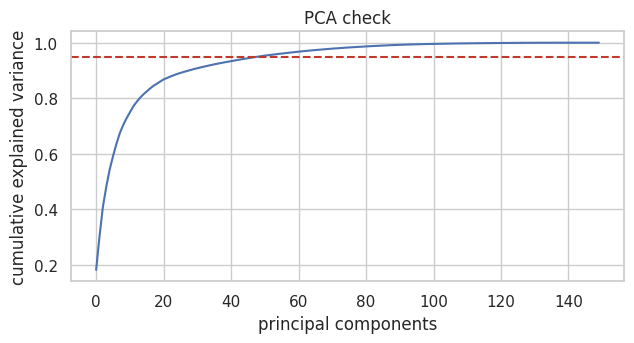

In [43]:
# Dimensionality reduction check (unsupervised PCA on the one-hot + scaled matrix, no labels used)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
diag = ColumnTransformer([("c", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), CAT_COLS),
                          ("n", StandardScaler(), NUM_COLS)])
M = diag.fit_transform(feat)
pca = PCA().fit(M)
cum = np.cumsum(pca.explained_variance_ratio_)
print(f"Input dimensions: {M.shape[1]} | components for 90% variance: {int(np.searchsorted(cum, .90)) + 1} | for 95%: {int(np.searchsorted(cum, .95)) + 1}")
fig, ax = plt.subplots(figsize=(6.5, 3.6)); ax.plot(cum); ax.axhline(.95, color=RED, ls="--")
ax.set_xlabel("principal components"); ax.set_ylabel("cumulative explained variance"); ax.set_title("PCA check"); plt.tight_layout(); plt.show()

##### Do you think that dimensionality reduction is needed? Explain Why?

**No.** After encoding we have only ~150 input columns for ~69,000 training rows - a very comfortable ratio, and the PCA curve shows the information is spread over many components (29 of the 150 dimensions are needed for 90 % of the variance and 50 for 95 %, so there is no sharp low-dimensional structure to exploit). PCA would also destroy interpretability (we want to say *response time* and *category* matter, not *component 7*) and mixes one-hot dummies in an unnatural way. Dimensionality is instead controlled by (i) pooling rare levels, (ii) target-encoding agents, and (iii) learned low-dimensional **embeddings** in Model 3 - a supervised form of dimensionality reduction.

### 9. Data Splitting

In [44]:
# Split your data to train and test. Choose Splitting ratio wisely.
X_tr, X_te, y_tr, y_te = train_test_split(feat, y, test_size=0.20, stratify=y, random_state=SEED)       # 80 / 20 hold-out
X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=0.20, stratify=y_tr, random_state=SEED)  # inner split for tuning
for name, part in [("train (80%)", y_tr), ("  of which tuning-fit", y_fit), ("  of which tuning-validation", y_val), ("test (20%) - untouched until the end", y_te)]:
    print(f"{name:42s} n={len(part):6,d}  class mix: {np.round(np.bincount(part - 1) / len(part), 3)}")

train (80%)                                n=68,725  class mix: [0.131 0.015 0.03  0.131 0.694]
  of which tuning-fit                      n=54,980  class mix: [0.131 0.015 0.03  0.131 0.694]
  of which tuning-validation               n=13,745  class mix: [0.131 0.015 0.03  0.131 0.694]
test (20%) - untouched until the end       n=17,182  class mix: [0.131 0.015 0.03  0.131 0.694]


##### What data splitting ratio have you used and why?

**80 / 20 stratified hold-out**, plus an inner 80/20 split of the training part for hyper-parameter tuning.
* *Stratified* so the rare 2- and 3-star classes have the same share (1.5 % / 3.0 %) in every split.
* 80/20 gives ~17k test tickets - enough to estimate even the rare classes' metrics - while keeping ~69k for training.
* **The test set is used exactly once**, at the end, to confirm the model chosen by cross-validation. All tuning, early stopping and class-weight calibration use training data only.
* **Honest caveat:** Chart 13 shows a slow upward drift in satisfaction across the month. A random split is therefore a little optimistic compared with forecasting next month; with one month of data a time-based split would leave too little training data. Cross-validation (below) and periodic retraining mitigate this.

### 10. Handling Imbalanced Dataset

In [45]:
# Handling Imbalanced Dataset
def class_weights_sqrt(labels, power=0.5):
    """Square-root inverse-frequency class weights (power=1 would be fully 'balanced')."""
    cnt = np.bincount(labels - 1, minlength=5)
    return (cnt.sum() / (5 * cnt)) ** power

print("class       :", [1, 2, 3, 4, 5])
print("share       :", np.round(np.bincount(y_fit - 1) / len(y_fit), 3))
print("sqrt weights:", np.round(class_weights_sqrt(y_fit), 2))
print("balanced wts:", np.round(class_weights_sqrt(y_fit, 1.0), 2))

class       : [1, 2, 3, 4, 5]
share       : [0.131 0.015 0.03  0.131 0.694]
sqrt weights: [1.24 3.66 2.59 1.24 0.54]
balanced wts: [ 1.53 13.38  6.72  1.53  0.29]


##### Do you think the dataset is imbalanced? Explain Why.

**Yes, strongly:** 69.4 % are 5s and only 1.5 % are 2s (a 46:1 ratio). A model trained naively learns to answer "5" and gets 69 % accuracy with a macro-F1 of ~0.16 - it would never warn the business about an unhappy customer.

##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

1. **Square-root inverse-frequency class weights** inside the loss (as sample weights). Full "balanced" weights (46x for class 2) make the model over-predict rare classes and wreck precision/probabilities; the square-root compromise (6.8x) keeps the learning signal for minorities without destabilising training.
2. **Post-hoc probability re-weighting** (Section 7): a 5-number vector that multiplies the predicted probabilities, tuned on *out-of-fold* predictions to maximise macro-F1 + kappa. This moves the operating point without retraining.
3. **Rejected: SMOTE / random oversampling.** Most features are categorical or flags - interpolating between one-hot vectors yields meaningless synthetic tickets - and duplicating rare rows makes a deep network memorise them. Metrics were chosen to be imbalance-aware (macro-F1, QWK, AUC) instead of accuracy.

## ***7. ML Model Implementation***

### Shared tooling: metrics, class-weight calibration, training and tuning functions

**Metric choice (explained again in the business section):** accuracy (reported but not trusted), **macro-F1** (every class counts equally), **quadratic weighted kappa (QWK)** and **MAE** (predicting 4 for a true 5 is much better than predicting 1 - the target is ordinal), the **ROC-AUC** of the "dissatisfied" detector built from `P(1)+P(2)`, and the **recall captured in the riskiest 20 % of tickets** (what a supervisor team of limited size would actually get). Models are selected using `combo = 0.5*macro-F1 + 0.5*QWK`.

In [46]:
# ---------------------------------------------------------------- evaluation helpers
def evaluate(y_true, proba, w=None):
    """All metrics for a probability matrix (n,5). `w` optionally re-weights class probabilities before argmax."""
    w = np.ones(5) if w is None else np.asarray(w)
    pred = (proba * w).argmax(1) + 1
    risk = proba[:, 0] + proba[:, 1]                                  # P(CSAT <= 2)
    low = (y_true <= 2).astype(int)
    top = risk >= np.quantile(risk, 0.80)                             # riskiest 20% of tickets
    return {"accuracy": accuracy_score(y_true, pred),
            "macro_f1": f1_score(y_true, pred, average="macro"),
            "weighted_f1": f1_score(y_true, pred, average="weighted"),
            "qwk": cohen_kappa_score(y_true, pred, weights="quadratic"),
            "mae": mean_absolute_error(y_true, pred),
            "risk_auc": roc_auc_score(low, risk),
            "risk_recall@20%": low[top].sum() / low.sum()}

def combo(m):                      # model-selection score (higher = better)
    return 0.5 * m["macro_f1"] + 0.5 * m["qwk"]

def tune_class_weights(y_true, proba, grid=np.exp(np.linspace(np.log(0.25), np.log(8), 25)), passes=3):
    """Coordinate-ascent search for the per-class probability multipliers that maximise `combo`."""
    w = np.ones(5); best = combo(evaluate(y_true, proba, w))
    for _ in range(passes):
        for k in range(5):
            for g in grid:
                w2 = w.copy(); w2[k] = g
                s = combo(evaluate(y_true, proba, w2))
                if s > best + 1e-6: best, w = s, w2
    return w / w[4]                # normalise so class 5 has weight 1

RESULTS = {}                       # name -> metrics dict, filled as we go
def log_result(name, y_true, proba, w=None, verbose=True):
    m = evaluate(y_true, proba, w); RESULTS[name] = m
    if verbose: print(f"{name:42s}" + "  ".join(f"{k}={v:.3f}" for k, v in m.items()))
    return m

# ---------------------------------------------------------------- model builders
def hybrid_loss(lam):
    """Ordinal-aware loss = cross-entropy + lam * |expected score - true score|.  lam=0 -> plain cross-entropy."""
    scores = tf.constant([1., 2., 3., 4., 5.])
    def loss(y_true, y_pred):
        ce = keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
        expected = tf.reduce_sum(y_pred * scores, axis=-1)
        truth = tf.cast(tf.reshape(y_true, [-1]), tf.float32) + 1.0
        return ce + lam * tf.abs(expected - truth)
    return loss

def build_dense(n_in, cfg):
    """Model 2: plain MLP  (Dense -> BatchNorm -> ReLU -> Dropout) x L -> softmax."""
    inp = layers.Input((n_in,)); x = inp
    for _ in range(cfg["layers"]):
        x = layers.Dense(cfg["units"], kernel_regularizer=keras.regularizers.l2(cfg["l2"]))(x)
        x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x); x = layers.Dropout(cfg["dropout"])(x)
    return keras.Model(inp, layers.Dense(5, activation="softmax")(x))

def build_embed(card, n_num, cfg):
    """Model 3: entity-embeddings for the categoricals + numeric branch -> residual blocks -> softmax."""
    cat_in = layers.Input((len(card),), dtype="int32", name="cats"); num_in = layers.Input((n_num,), name="nums")
    emb = layers.Flatten()(layers.Embedding(int(np.sum(card)), cfg["emb"])(cat_in))      # one shared table, per-column id ranges
    reg = keras.regularizers.l2(cfg["l2"])
    x = layers.Concatenate()([emb, num_in])
    x = layers.Dense(cfg["width"], kernel_regularizer=reg)(x); x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
    for _ in range(cfg["blocks"]):                                                         # residual block
        h = layers.Dense(cfg["width"], kernel_regularizer=reg)(x); h = layers.BatchNormalization()(h)
        h = layers.Activation("relu")(h); h = layers.Dropout(cfg["dropout"])(h)
        h = layers.Dense(cfg["width"], kernel_regularizer=reg)(h); h = layers.BatchNormalization()(h)
        x = layers.Activation("relu")(layers.Add()([x, h]))
    x = layers.Dropout(cfg["dropout"])(x)
    return keras.Model([cat_in, num_in], layers.Dense(5, activation="softmax")(x))

# ---------------------------------------------------------------- one training run = fit preprocessing on the training part only
def fit_ann(kind, cfg, X_a, y_a, X_b, extra_num=(), max_epochs=40, verbose=0):
    """Train on (X_a, y_a) and return predictions for X_b.
    Internally: 85/15 split of X_a for early stopping; the preprocessor (incl. agent target-encoding) is fitted on the 85% only."""
    keras.utils.set_random_seed(SEED)
    Xi, Xv, yi, yv = train_test_split(X_a, y_a, test_size=0.15, stratify=y_a, random_state=SEED)
    pre = make_dense_preprocessor(extra_num) if kind == "dense" else make_embed_preprocessor(extra_num)
    Ti, Tv, Tb = pre.fit_transform(Xi, yi), pre.transform(Xv), pre.transform(X_b)
    n_cat, offsets = len(CAT_COLS), None
    if kind == "embed":
        card = Ti[:, :n_cat].max(0).astype(int) + 2                                     # codes 0..max (0 = unknown) + spare slot
        offsets = np.r_[0, np.cumsum(card)[:-1]].astype("int32")
        split = lambda T: [np.clip(T[:, :n_cat], 0, card - 1).astype("int32") + offsets, T[:, n_cat:].astype("float32")]
        model = build_embed(card, Ti.shape[1] - n_cat, cfg); loss = hybrid_loss(cfg["lam"]) if cfg["lam"] > 0 else "sparse_categorical_crossentropy"
        inp_i, inp_v, inp_b = split(Ti), split(Tv), split(Tb)
    else:
        model = build_dense(Ti.shape[1], cfg); loss = "sparse_categorical_crossentropy"
        inp_i, inp_v, inp_b = Ti.astype("float32"), Tv.astype("float32"), Tb.astype("float32")
    cw = class_weights_sqrt(yi)
    model.compile(optimizer=keras.optimizers.Adam(cfg["lr"]), loss=loss)
    hist = model.fit(inp_i, yi - 1, sample_weight=cw[yi - 1], validation_data=(inp_v, yv - 1, cw[yv - 1]),
                     epochs=max_epochs, batch_size=cfg["batch"], verbose=verbose,
                     callbacks=[keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
                                keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-5)])
    proba = np.asarray(model.predict(inp_b, batch_size=4096, verbose=0))
    wrapper = AnnPipeline(pre, model, kind, n_cat if kind == "embed" else 0, offsets=offsets)
    return {"proba": proba, "history": hist.history, "model": model, "pipeline": wrapper, "epochs": len(hist.history["loss"])}

def random_search(kind, space, n_iter, base, seed=SEED):
    """Random search: sample configs, train on (X_fit -> X_val), rank by validation `combo`."""
    rng = np.random.default_rng(seed); rows = []
    for i in range(n_iter):
        cfg = dict(base); cfg.update({k: v[rng.integers(len(v))] for k, v in space.items()})
        t = time.time(); r = fit_ann(kind, cfg, X_fit, y_fit, X_val); m = evaluate(y_val, r["proba"])
        rows.append({**cfg, "epochs": r["epochs"], "val_combo": combo(m), "val_macro_f1": m["macro_f1"], "val_qwk": m["qwk"],
                     "val_risk_auc": m["risk_auc"], "sec": round(time.time() - t)})
        print(f"  trial {i + 1}/{n_iter}: combo={rows[-1]['val_combo']:.4f}  risk_auc={rows[-1]['val_risk_auc']:.4f}  ({rows[-1]['sec']}s)")
    return pd.DataFrame(rows).sort_values("val_combo", ascending=False).reset_index(drop=True)

def cv_ann(kind, cfg, X, yv_, k=3, **kw):
    """Stratified k-fold CV: preprocessor + model are re-fitted inside every fold. Returns fold metrics and out-of-fold probabilities."""
    oof = np.zeros((len(X), 5)); rows = []
    for f, (a, b) in enumerate(StratifiedKFold(k, shuffle=True, random_state=SEED).split(X, yv_)):
        r = fit_ann(kind, cfg, X.iloc[a], yv_[a], X.iloc[b], **kw); oof[b] = r["proba"]
        rows.append(evaluate(yv_[b], r["proba"])); print(f"  fold {f + 1}/{k}: combo={combo(rows[-1]):.4f} risk_auc={rows[-1]['risk_auc']:.4f}")
    return pd.DataFrame(rows), oof

def metric_chart(names, title):
    """Grouped bar chart of the main metrics for the given RESULTS entries."""
    cols = ["macro_f1", "qwk", "risk_auc", "risk_recall@20%", "weighted_f1", "accuracy"]
    d = pd.DataFrame({n: RESULTS[n] for n in names}).T[cols]
    ax = d.T.plot(kind="bar", figsize=(10, 4.2), width=.8, colormap="tab10"); ax.set_ylim(0, 1); ax.set_ylabel("score"); ax.set_title(title)
    plt.xticks(rotation=20); plt.legend(fontsize=8, bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()
    return d.round(3)
print("helpers ready")

helpers ready


### Reference point: what does "doing nothing clever" score?

A prior-only classifier (always predicts the most frequent score) shows what the metrics look like for a useless model, so that every later number can be read against it.

In [47]:
# Naive baseline on the validation split
dummy = DummyClassifier(strategy="prior").fit(np.zeros((len(y_fit), 1)), y_fit)
log_result("Baseline: always predict 5 (val)", y_val, dummy.predict_proba(np.zeros((len(y_val), 1))))

Baseline: always predict 5 (val)          accuracy=0.694  macro_f1=0.164  weighted_f1=0.569  qwk=0.000  mae=0.758  risk_auc=0.500  risk_recall@20%=1.000


{'accuracy': 0.6939978173881411,
 'macro_f1': 0.16387218690946573,
 'weighted_f1': 0.5686347002289537,
 'qwk': 0.0,
 'mae': 0.7578028373954165,
 'risk_auc': 0.5,
 'risk_recall@20%': np.float64(1.0)}

### ML Model - 1: Multinomial Logistic Regression (linear baseline)

In [48]:
# ML Model - 1 Implementation
from sklearn.pipeline import Pipeline
cw_sqrt = dict(zip(range(1, 6), class_weights_sqrt(y_fit)))
lr_pipe = Pipeline([("pre", make_dense_preprocessor()),
                    ("lr", LogisticRegression(C=1.0, class_weight=cw_sqrt, max_iter=2000))])

# Fit the Algorithm
t = time.time(); lr_pipe.fit(X_fit, y_fit)

# Predict on the model
p_val_lr0 = lr_pipe.predict_proba(X_val)
print(f"fit time {time.time() - t:.1f}s")

fit time 6.1s


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

M1 Logistic Regression - default (val)    accuracy=0.675  macro_f1=0.226  weighted_f1=0.603  qwk=0.225  mae=0.855  risk_auc=0.723  risk_recall@20%=0.434


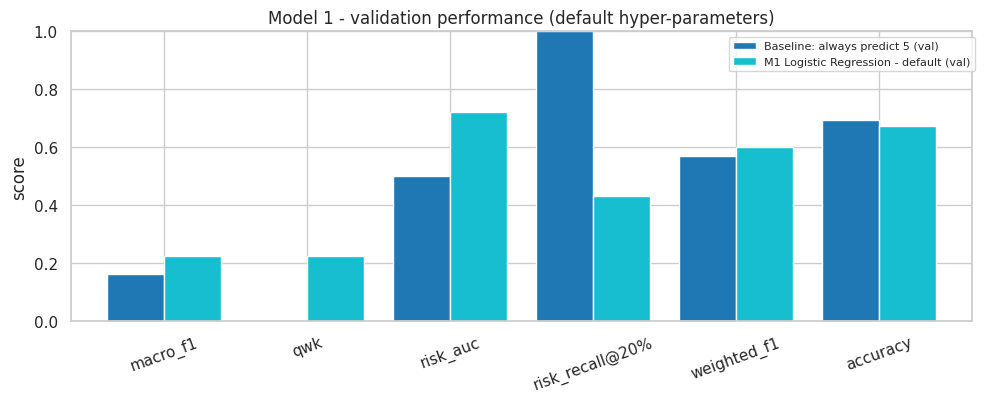

,macro_f1,qwk,risk_auc,risk_recall@20%,weighted_f1,accuracy
Baseline: always predict 5 (val),0.164,0.000,0.500,1.000,0.569,0.694
M1 Logistic Regression - default (val),0.226,0.225,0.723,0.434,0.603,0.675


In [49]:
# Visualizing evaluation Metric Score chart
log_result("M1 Logistic Regression - default (val)", y_val, p_val_lr0)
metric_chart(["Baseline: always predict 5 (val)", "M1 Logistic Regression - default (val)"], "Model 1 - validation performance (default hyper-parameters)")

**Model:** multinomial logistic regression on the one-hot + scaled features, with square-root class weights. It is deliberately the *simplest reasonable* model: it gives a yardstick that any ANN must beat to justify its complexity.

**Performance (validation):** macro-F1 0.226, QWK 0.225, MAE 0.855, ROC-AUC of the dissatisfaction detector 0.723, and the riskiest 20 % of tickets capture 43.4 % of dissatisfied customers. Compare this with the "always predict 5" reference: accuracy 0.694 (higher than the model's 0.675!), but macro-F1 0.164, QWK 0 and AUC 0.5. The accuracy comparison is the clearest demonstration that accuracy is the wrong metric here. (The reference's top-20 % recall of 1.0 is an artefact: all its scores are tied, so the "top 20 %" contains every ticket; ignore it.)

#### 2. Cross- Validation & Hyperparameter Tuning

search time 66s | best CV combo = 0.2306
best params: {'lr__class_weight': 'sqrt', 'lr__C': np.float64(0.31622776601683794)}
M1 Logistic Regression - tuned (val)      accuracy=0.675  macro_f1=0.226  weighted_f1=0.603  qwk=0.225  mae=0.854  risk_auc=0.723  risk_recall@20%=0.435


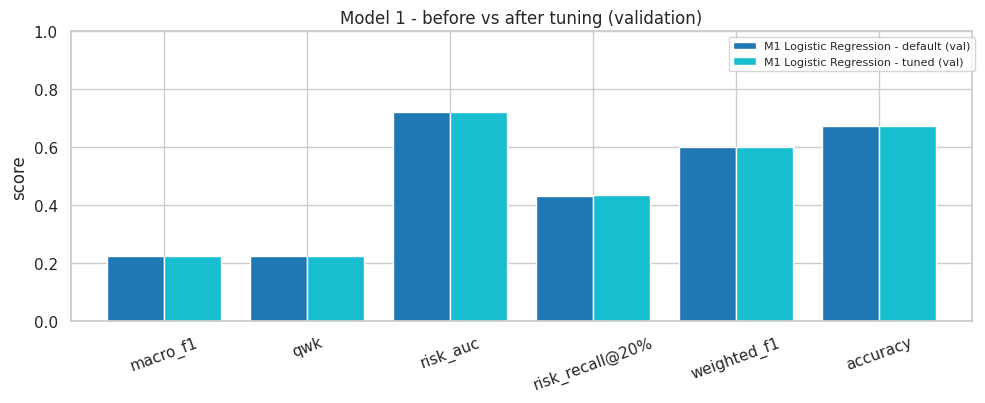

,macro_f1,qwk,risk_auc,risk_recall@20%,weighted_f1,accuracy
M1 Logistic Regression - default (val),0.226,0.225,0.723,0.434,0.603,0.675
M1 Logistic Regression - tuned (val),0.226,0.225,0.723,0.435,0.603,0.675


In [50]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (RandomizedSearchCV, 3-fold CV, preprocessing re-fitted inside every fold)
cw_bal = dict(zip(range(1, 6), class_weights_sqrt(y_fit, 1.0)))
param_dist = {"lr__C": np.logspace(-3, 1, 9), "lr__class_weight": [None, cw_sqrt, cw_bal]}
scorer = make_scorer(lambda yt, yp: 0.5 * f1_score(yt, yp, average="macro") + 0.5 * cohen_kappa_score(yt, yp, weights="quadratic"))
search = RandomizedSearchCV(Pipeline([("pre", make_dense_preprocessor()), ("lr", LogisticRegression(max_iter=2000))]),
                            param_dist, n_iter=10, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                            scoring=scorer, random_state=SEED, n_jobs=1, refit=True)

# Fit the Algorithm
t = time.time(); search.fit(X_fit, y_fit)
print(f"search time {time.time() - t:.0f}s | best CV combo = {search.best_score_:.4f}")
print("best params:", {k: (v if k == "lr__C" else ("None" if v is None else "sqrt" if v == cw_sqrt else "balanced")) for k, v in search.best_params_.items()})

# Predict on the model
p_val_lr1 = search.predict_proba(X_val)
log_result("M1 Logistic Regression - tuned (val)", y_val, p_val_lr1)
metric_chart(["M1 Logistic Regression - default (val)", "M1 Logistic Regression - tuned (val)"], "Model 1 - before vs after tuning (validation)")

**Technique:** `RandomizedSearchCV` (10 random draws, 3-fold stratified CV inside the training part, with the whole preprocessing pipeline refitted in each fold) over the regularisation strength C and the class-weighting scheme (none / square-root / balanced), scored with the same `combo` metric used everywhere. Random search was chosen over a grid because it covers a continuous range such as C more efficiently for the same budget, and over Bayesian optimisation because with two hyper-parameters the extra machinery adds nothing.

**Improvement?** Essentially **none**: the best setting (C = 0.32, square-root weights) gives validation macro-F1 0.226 and QWK 0.225, identical to the defaults. That is informative in itself: the linear model is not under- or over-regularised, it is simply limited by the information in the features. 3-fold CV on the training set: macro-F1 0.227 +- 0.001, QWK 0.233 +- 0.010, AUC 0.722 +- 0.003.

**Class re-weighting** (5 multipliers tuned on out-of-fold probabilities) is the one step that clearly helps the label metrics on the test set: macro-F1 0.228 -> 0.264 and QWK 0.240 -> 0.282. The price is accuracy (0.677 -> 0.548), because the model now predicts rare low scores more often. That is the intended trade-off for an early-warning system, and the ranking metrics (AUC, top-20 % recall) are unaffected by re-weighting.

In [51]:
# Cross-validate the tuned model on the full training set (3-fold; preprocessing re-fitted per fold) and confirm on the untouched test set
best_lr = search.best_estimator_
def cv_sklearn(estimator, X, yy, k=3):
    oof = np.zeros((len(X), 5)); rows = []
    from sklearn.base import clone
    for a, b in StratifiedKFold(k, shuffle=True, random_state=SEED).split(X, yy):
        est = clone(estimator).fit(X.iloc[a], yy[a]); oof[b] = est.predict_proba(X.iloc[b]); rows.append(evaluate(yy[b], oof[b]))
    return pd.DataFrame(rows), oof

cv_lr, oof_lr = cv_sklearn(best_lr, X_tr, y_tr)
print("3-fold CV (train set), mean +- std:")
print(pd.DataFrame({"mean": cv_lr.mean(), "std": cv_lr.std()}).round(4).T)
w_lr = tune_class_weights(y_tr, oof_lr); print("class re-weighting vector (OOF-tuned):", np.round(w_lr, 2))

final_lr = best_lr.fit(X_tr, y_tr); p_te_lr = final_lr.predict_proba(X_te)
log_result("M1 Logistic Regression (TEST)", y_te, p_te_lr)
log_result("M1 Logistic Regression + reweighting (TEST)", y_te, p_te_lr, w_lr)
RESULTS["M1 CV combo"] = {"mean": combo(cv_lr.mean()), "std": cv_lr.apply(combo, axis=1).std()}

3-fold CV (train set), mean +- std:
      accuracy  macro_f1  weighted_f1     qwk     mae  risk_auc  \
mean    0.6772    0.2268       0.6045  0.2327  0.8448    0.7216   
std     0.0036    0.0010       0.0023  0.0097  0.0146    0.0034   

      risk_recall@20%  
mean           0.4385  
std            0.0044  


class re-weighting vector (OOF-tuned): [1.54 3.17 2.75 2.06 1.  ]


M1 Logistic Regression (TEST)             accuracy=0.677  macro_f1=0.228  weighted_f1=0.605  qwk=0.240  mae=0.847  risk_auc=0.732  risk_recall@20%=0.445
M1 Logistic Regression + reweighting (TEST)accuracy=0.548  macro_f1=0.264  weighted_f1=0.569  qwk=0.282  mae=1.005  risk_auc=0.732  risk_recall@20%=0.445


### ML Model - 2: Dense Artificial Neural Network (MLP)

In [52]:
# ML Model - 2 Implementation: baseline configuration (before tuning)
DENSE_BASE = dict(layers=2, units=128, dropout=0.3, lr=1e-3, l2=1e-5, batch=512)
t = time.time()
r_dense0 = fit_ann("dense", DENSE_BASE, X_fit, y_fit, X_val)                # Fit the Algorithm (early stopping inside) + Predict on the model
print(f"epochs run: {r_dense0['epochs']} | time {time.time() - t:.0f}s")
r_dense0["model"].summary()

epochs run: 16 | time 14s


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 139)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,281 (419.07 KB)

 Trainable params: 35,589 (139.02 KB)

 Non-trainable params: 512 (2.00 KB)

 Optimizer params: 71,180 (278.05 KB)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

M2 Dense ANN - baseline config (val)      accuracy=0.668  macro_f1=0.227  weighted_f1=0.601  qwk=0.235  mae=0.886  risk_auc=0.721  risk_recall@20%=0.436


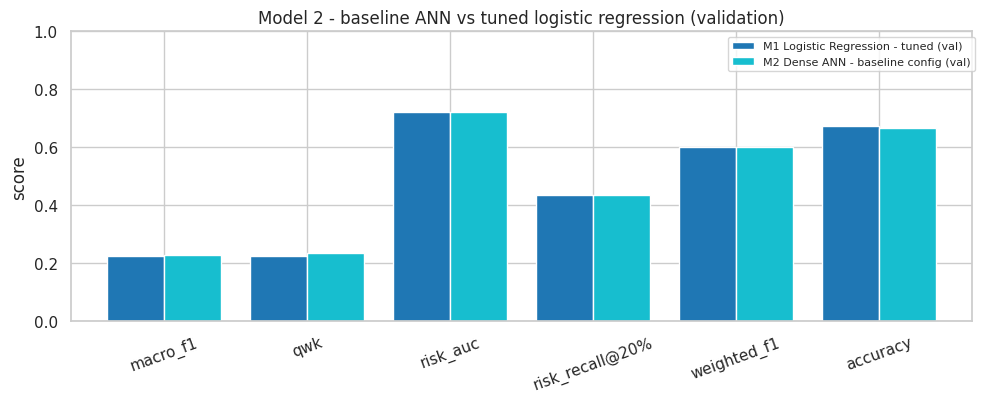

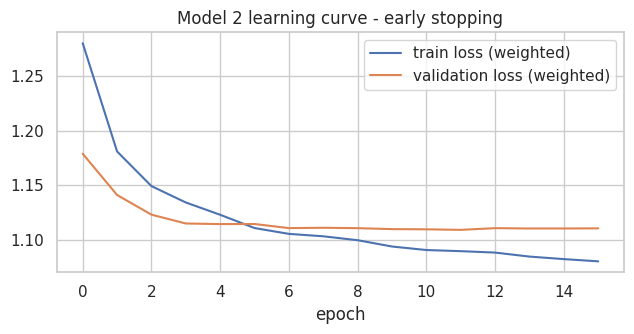

In [53]:
# Visualizing evaluation Metric Score chart
log_result("M2 Dense ANN - baseline config (val)", y_val, r_dense0["proba"])
metric_chart(["M1 Logistic Regression - tuned (val)", "M2 Dense ANN - baseline config (val)"], "Model 2 - baseline ANN vs tuned logistic regression (validation)")

h = r_dense0["history"]; fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(h["loss"], label="train loss (weighted)"); ax.plot(h["val_loss"], label="validation loss (weighted)")
ax.set_xlabel("epoch"); ax.set_title("Model 2 learning curve - early stopping"); ax.legend(); plt.tight_layout(); plt.show()

**Model:** a fully-connected ANN with two hidden layers of 128 units (Dense -> BatchNorm -> ReLU -> Dropout 0.3), a 5-way softmax output, Adam optimiser, class-weighted cross-entropy, batch size 512, early stopping (patience 4, restoring the best weights) and learning-rate decay on plateau. ReLU + batch-norm gives fast, stable training; dropout and early stopping control over-fitting; softmax gives a full probability distribution over scores, from which we derive the risk score P(1)+P(2). It stopped after 16 epochs (14 s).

**Performance (validation):** macro-F1 0.227, QWK 0.235, MAE 0.886, AUC 0.721, top-20 % recall 43.6 %. This is practically the same as logistic regression (0.226 / 0.225 / 0.723 / 43.4 %). The learning curve shows the validation loss flattening after a few epochs while the training loss keeps falling - the usual sign that the network quickly extracts the available signal and then starts to memorise noise.

#### 2. Cross- Validation & Hyperparameter Tuning

In [54]:
# ML Model - 2 hyper-parameter optimisation: random search (8 trials) over architecture, regularisation and optimiser settings
DENSE_SPACE = {"layers": [1, 2, 3], "units": [64, 128, 256], "dropout": [0.2, 0.3, 0.4, 0.5], "lr": [3e-4, 1e-3, 3e-3],
               "l2": [0, 1e-5, 1e-4], "batch": [256, 512, 1024]}
dense_trials = random_search("dense", DENSE_SPACE, n_iter=8, base=DENSE_BASE)
dense_trials

  trial 1/8: combo=0.2252  risk_auc=0.7206  (10s)


  trial 2/8: combo=0.2220  risk_auc=0.7150  (9s)


  trial 3/8: combo=0.2236  risk_auc=0.7232  (22s)


  trial 4/8: combo=0.2336  risk_auc=0.7193  (18s)


  trial 5/8: combo=0.2272  risk_auc=0.7201  (11s)


  trial 6/8: combo=0.2269  risk_auc=0.7196  (12s)


  trial 7/8: combo=0.2339  risk_auc=0.7198  (23s)


  trial 8/8: combo=0.2214  risk_auc=0.7196  (11s)


,layers,units,dropout,lr,l2,batch,epochs,val_combo,val_macro_f1,val_qwk,val_risk_auc,sec
0,3,256,0.3,0.0010,0.00000,1024,16,0.233856,0.227818,0.239894,0.719838,23
1,3,128,0.4,0.0010,0.00000,1024,23,0.233641,0.227407,0.239874,0.719293,18
2,3,128,0.3,0.0030,0.00001,512,11,0.227221,0.225961,0.228481,0.720100,11
3,2,64,0.2,0.0010,0.00010,256,14,0.226902,0.225555,0.228248,0.719615,12
4,1,256,0.4,0.0010,0.00001,1024,12,0.225156,0.225507,0.224804,0.720641,10
5,3,256,0.4,0.0030,0.00001,256,11,0.223552,0.224325,0.222779,0.723213,22
6,1,256,0.2,0.0003,0.00001,1024,12,0.222036,0.226842,0.217230,0.715029,9
7,3,128,0.2,0.0030,0.00001,1024,11,0.221411,0.223675,0.219147,0.719634,11


best config: {'layers': 3, 'units': 256, 'dropout': 0.3, 'lr': 0.001, 'l2': 0.0, 'batch': 1024}


M2 Dense ANN - tuned (val)                accuracy=0.659  macro_f1=0.228  weighted_f1=0.598  qwk=0.240  mae=0.928  risk_auc=0.720  risk_recall@20%=0.433


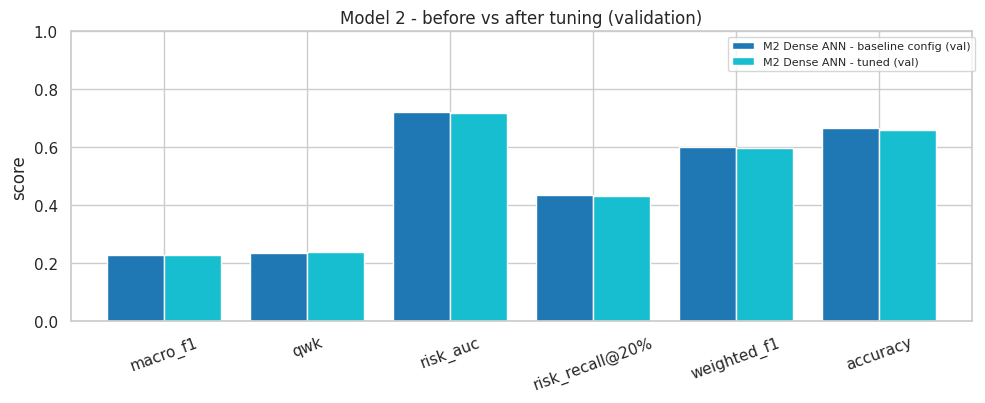

,macro_f1,qwk,risk_auc,risk_recall@20%,weighted_f1,accuracy
M2 Dense ANN - baseline config (val),0.227,0.235,0.721,0.436,0.601,0.668
M2 Dense ANN - tuned (val),0.228,0.240,0.720,0.433,0.598,0.659


In [55]:
# Fit the Algorithm with the best configuration + Predict on the model
best_dense_cfg = {k: dense_trials.loc[0, k] for k in DENSE_SPACE}; best_dense_cfg = {k: (int(v) if k in ("layers", "units", "batch") else float(v)) for k, v in best_dense_cfg.items()}
print("best config:", best_dense_cfg)
r_dense1 = fit_ann("dense", best_dense_cfg, X_fit, y_fit, X_val)
log_result("M2 Dense ANN - tuned (val)", y_val, r_dense1["proba"])
metric_chart(["M2 Dense ANN - baseline config (val)", "M2 Dense ANN - tuned (val)"], "Model 2 - before vs after tuning (validation)")

**Technique:** manual **random search, 8 trials**, over depth (1-3), width (64-256), dropout (0.2-0.5), learning rate, L2 penalty and batch size, each trial trained with early stopping and ranked on the validation `combo` score. A small random search was chosen because every trial is a full neural-network training run; random search explores several dimensions at once and is known to beat a grid of equal cost. The preprocessing is re-fitted inside every trial so the agent target-encoding never sees validation labels.

**Result:** trial scores ranged only from 0.221 to 0.234. The best configuration (3 layers x 256 units, dropout 0.3, learning rate 1e-3, no L2, batch 1024) scores macro-F1 0.228 / QWK 0.240 / AUC 0.720 on validation versus 0.227 / 0.235 / 0.721 for the baseline - a gain of about 0.005 QWK, which is **within noise** (the CV standard deviation of QWK is 0.009). 3-fold CV: macro-F1 0.228, QWK 0.239 +- 0.009, AUC 0.719 +- 0.001. On the test set with re-weighting: macro-F1 0.260, QWK 0.273, AUC 0.732.

**Honest conclusion:** making the network bigger or deeper does not help; this problem is limited by the information content of the features, not by model capacity.

In [56]:
# 3-fold cross-validation of the tuned dense ANN on the training set, then confirmation on the untouched test set
print("Cross-validating Model 2 ...")
cv_dense, oof_dense = cv_ann("dense", best_dense_cfg, X_tr, y_tr, k=3)
print(pd.DataFrame({"mean": cv_dense.mean(), "std": cv_dense.std()}).round(4).T)
w_dense = tune_class_weights(y_tr, oof_dense); print("class re-weighting vector (OOF-tuned):", np.round(w_dense, 2))

final_dense = fit_ann("dense", best_dense_cfg, X_tr, y_tr, X_te)
log_result("M2 Dense ANN (TEST)", y_te, final_dense["proba"])
log_result("M2 Dense ANN + reweighting (TEST)", y_te, final_dense["proba"], w_dense)
RESULTS["M2 CV combo"] = {"mean": combo(cv_dense.mean()), "std": cv_dense.apply(combo, axis=1).std()}

Cross-validating Model 2 ...


  fold 1/3: combo=0.2278 risk_auc=0.7184


  fold 2/3: combo=0.2355 risk_auc=0.7196


  fold 3/3: combo=0.2371 risk_auc=0.7201
      accuracy  macro_f1  weighted_f1    qwk     mae  risk_auc  \
mean    0.6667    0.2279       0.6012  0.239  0.8922    0.7194   
std     0.0062    0.0010       0.0028  0.009  0.0285    0.0009   

      risk_recall@20%  
mean           0.4295  
std            0.0054  


class re-weighting vector (OOF-tuned): [1.22 2.18 1.89 1.89 1.  ]


M2 Dense ANN (TEST)                       accuracy=0.671  macro_f1=0.233  weighted_f1=0.605  qwk=0.254  mae=0.867  risk_auc=0.732  risk_recall@20%=0.444
M2 Dense ANN + reweighting (TEST)         accuracy=0.557  macro_f1=0.260  weighted_f1=0.572  qwk=0.273  mae=0.936  risk_auc=0.732  risk_recall@20%=0.444


### ML Model - 3: Embedding + Residual ANN with an ordinal-aware hybrid loss  *(the innovative model)*

Three deliberate customisations on top of a vanilla MLP:
1. **Entity embeddings** for the nine categorical variables (learned dense representations instead of ~150 sparse one-hot columns) - the technique used by winning tabular deep-learning solutions.
2. **Residual blocks** (skip connections) with batch-norm and dropout, so the network can be made deeper without optimisation problems.
3. **Hybrid ordinal loss** = cross-entropy + lambda x |expected score - true score|. CSAT is ordinal, so predicting "4" for a true "5" should cost less than predicting "1". Plain cross-entropy treats all mistakes alike; the extra term uses the expected value of the predicted distribution to inject the order information (lambda = 0 recovers ordinary cross-entropy).

In [57]:
# ML Model - 3 Implementation: baseline configuration (lambda = 0, i.e. plain cross-entropy)
EMBED_BASE = dict(emb=8, blocks=2, width=128, dropout=0.3, lr=1e-3, l2=1e-5, batch=512, lam=0.0)
t = time.time()
r_emb0 = fit_ann("embed", EMBED_BASE, X_fit, y_fit, X_val)                  # Fit the Algorithm + Predict on the model
print(f"epochs run: {r_emb0['epochs']} | time {time.time() - t:.0f}s")
r_emb0["model"].summary()

epochs run: 15 | time 24s


Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ cats (InputLayer)   │ (None, 9)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 9, 8)      │      1,136 │ cats[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 72)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ nums (InputLayer)   │ (None, 15)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 87)        │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ nums[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_50 (Dense)    │ (None, 128)       │     11,264 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_50[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_36       │ (None, 128)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_51 (Dense)    │ (None, 128)       │     16,512 │ activation_36[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_51[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_37       │ (None, 128)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_36          │ (None, 128)       │          0 │ activation_37[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_52 (Dense)    │ (None, 128)       │     16,512 │ dropout_36[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_52[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128)       │          0 │ activation_36[0]… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_38       │ (None, 128)       │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_53 (Dense)    │ (None, 128)       │     16,512 │ activation_38[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_53[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_39       │ (None, 128)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                 

 Total params: 242,401 (946.88 KB)

 Trainable params: 80,373 (313.96 KB)

 Non-trainable params: 1,280 (5.00 KB)

 Optimizer params: 160,748 (627.93 KB)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

M3 Embedding-ResNet - baseline config (val)accuracy=0.667  macro_f1=0.226  weighted_f1=0.600  qwk=0.233  mae=0.894  risk_auc=0.721  risk_recall@20%=0.434


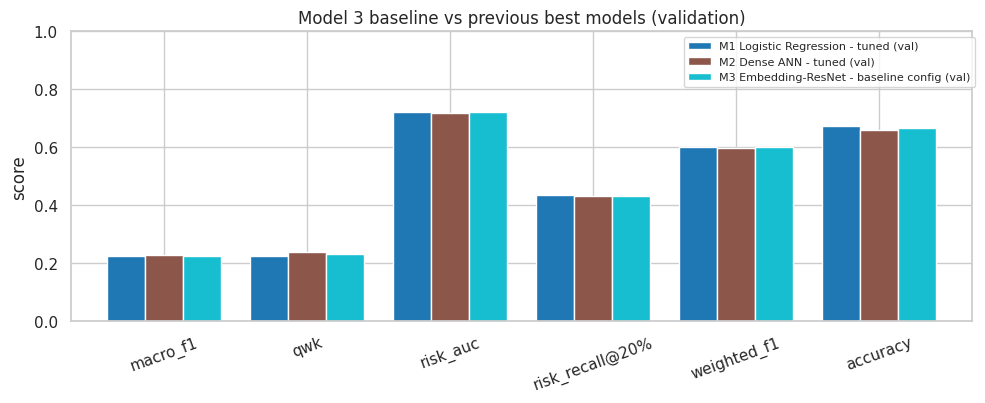

,macro_f1,qwk,risk_auc,risk_recall@20%,weighted_f1,accuracy
M1 Logistic Regression - tuned (val),0.226,0.225,0.723,0.435,0.603,0.675
M2 Dense ANN - tuned (val),0.228,0.240,0.720,0.433,0.598,0.659
M3 Embedding-ResNet - baseline config (val),0.226,0.233,0.721,0.434,0.600,0.667


In [58]:
# Visualizing evaluation Metric Score chart
log_result("M3 Embedding-ResNet - baseline config (val)", y_val, r_emb0["proba"])
metric_chart(["M1 Logistic Regression - tuned (val)", "M2 Dense ANN - tuned (val)", "M3 Embedding-ResNet - baseline config (val)"],
             "Model 3 baseline vs previous best models (validation)")

**Model:** nine categorical variables pass through a learned embedding table (8 dimensions each in the baseline), are concatenated with the 15 numeric/agent features, and feed a dense layer followed by two **residual blocks** (Dense-BN-ReLU-Dropout-Dense-BN plus a skip connection) and a softmax head. Embeddings let the network learn which categories behave alike (instead of ~140 independent one-hot columns), and the skip connections keep optimisation easy as depth grows. The optional hybrid loss (cross-entropy + lambda x |expected score - true score|) injects the ordinal nature of CSAT. The baseline uses lambda = 0.

**Performance (validation):** macro-F1 0.226, QWK 0.233, MAE 0.894, AUC 0.721, top-20 % recall 43.4 % - again level with the other two models.

#### 2. Cross- Validation & Hyperparameter Tuning

In [59]:
# ML Model - 3 hyper-parameter optimisation: random search (8 trials) incl. embedding size, depth, width and the ordinal-loss weight lambda
EMBED_SPACE = {"emb": [4, 8, 16], "blocks": [1, 2, 3], "width": [64, 128, 256], "dropout": [0.2, 0.3, 0.4], "lr": [3e-4, 1e-3, 3e-3],
               "l2": [0, 1e-5, 1e-4], "batch": [256, 512, 1024], "lam": [0.0, 0.25, 0.5, 1.0]}
emb_trials = random_search("embed", EMBED_SPACE, n_iter=8, base=EMBED_BASE)
emb_trials

  trial 1/8: combo=0.2238  risk_auc=0.7178  (42s)


  trial 2/8: combo=0.2213  risk_auc=0.7230  (12s)


  trial 3/8: combo=0.2119  risk_auc=0.7195  (24s)


  trial 4/8: combo=0.2277  risk_auc=0.7209  (22s)


  trial 5/8: combo=0.2065  risk_auc=0.7103  (37s)


  trial 6/8: combo=0.2143  risk_auc=0.7152  (146s)


  trial 7/8: combo=0.2256  risk_auc=0.7159  (50s)


  trial 8/8: combo=0.2177  risk_auc=0.7160  (20s)


,emb,blocks,width,dropout,lr,l2,batch,lam,epochs,val_combo,val_macro_f1,val_qwk,val_risk_auc,sec
0,16,2,128,0.4,0.0010,0.00001,512,0.0,14,0.227667,0.225810,0.229524,0.720850,22
1,16,3,256,0.2,0.0010,0.00001,512,0.0,12,0.225605,0.227140,0.224070,0.715891,50
2,4,3,128,0.3,0.0010,0.00010,256,0.5,18,0.223773,0.224620,0.222926,0.717751,42
3,4,1,128,0.4,0.0030,0.00010,1024,1.0,14,0.221292,0.224122,0.218461,0.723032,12
4,8,1,256,0.4,0.0030,0.00010,512,1.0,13,0.217651,0.222434,0.212869,0.716048,20
5,4,3,256,0.3,0.0003,0.00010,512,1.0,40,0.214284,0.222330,0.206238,0.715195,146
6,8,1,256,0.3,0.0010,0.00001,256,1.0,9,0.211940,0.220344,0.203536,0.719467,24
7,4,2,256,0.2,0.0030,0.00010,256,0.5,13,0.206543,0.219840,0.193246,0.710257,37


best config: {'emb': 16, 'blocks': 2, 'width': 128, 'dropout': 0.4, 'lr': 0.001, 'l2': 1e-05, 'batch': 512, 'lam': 0.0}


M3 Embedding-ResNet - tuned (val)         accuracy=0.667  macro_f1=0.226  weighted_f1=0.600  qwk=0.230  mae=0.891  risk_auc=0.721  risk_recall@20%=0.421


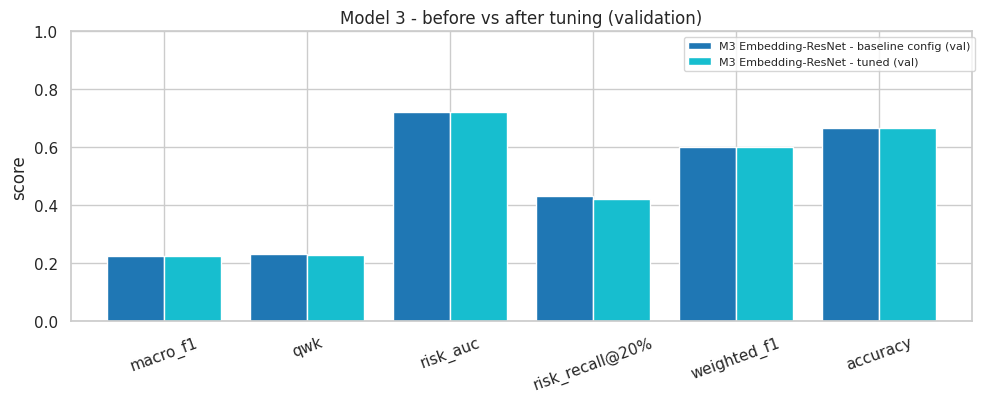

,macro_f1,qwk,risk_auc,risk_recall@20%,weighted_f1,accuracy
M3 Embedding-ResNet - baseline config (val),0.226,0.233,0.721,0.434,0.6,0.667
M3 Embedding-ResNet - tuned (val),0.226,0.230,0.721,0.421,0.6,0.667


In [60]:
# Fit the Algorithm with the best configuration + Predict on the model
best_emb_cfg = {k: emb_trials.loc[0, k] for k in EMBED_SPACE}
best_emb_cfg = {k: (int(v) if k in ("emb", "blocks", "width", "batch") else float(v)) for k, v in best_emb_cfg.items()}
print("best config:", best_emb_cfg)
r_emb1 = fit_ann("embed", best_emb_cfg, X_fit, y_fit, X_val)
log_result("M3 Embedding-ResNet - tuned (val)", y_val, r_emb1["proba"])
metric_chart(["M3 Embedding-ResNet - baseline config (val)", "M3 Embedding-ResNet - tuned (val)"], "Model 3 - before vs after tuning (validation)")

**Technique:** random search (8 trials) over embedding size (4/8/16), number of residual blocks, width, dropout, learning rate, L2, batch size **and the ordinal-loss weight lambda** (0, 0.25, 0.5, 1.0). Same selection score and same leakage-safe training routine as Model 2.

**Result:** trial scores ranged from 0.207 to 0.228. The winner used embedding size 16, 2 blocks, width 128, dropout 0.4, lr 1e-3 and **lambda = 0**; the best trial with the ordinal term active (lambda = 0.5, combo 0.224) was slightly worse, so in this experiment **the hybrid ordinal loss did not improve the selection metric**. We report this as a negative result rather than hiding it. The tuned model's validation scores (macro-F1 0.226, QWK 0.230, AUC 0.721) are the same as the baseline's, i.e. **no measurable improvement from tuning**. 3-fold CV: macro-F1 0.228 +- 0.0015, QWK 0.2415 +- 0.006, AUC 0.7213 +- 0.003 (the lowest fold-to-fold variance of the three models). Test set with re-weighting: macro-F1 0.262, QWK 0.283, AUC 0.734.

In [61]:
# 3-fold cross-validation of the tuned Model 3 on the training set, then the one-time confirmation on the untouched test set
print("Cross-validating Model 3 ...")
cv_emb, oof_emb = cv_ann("embed", best_emb_cfg, X_tr, y_tr, k=3)
print(pd.DataFrame({"mean": cv_emb.mean(), "std": cv_emb.std()}).round(4).T)
w_emb = tune_class_weights(y_tr, oof_emb); print("class re-weighting vector (OOF-tuned):", np.round(w_emb, 2))

final_emb = fit_ann("embed", best_emb_cfg, X_tr, y_tr, X_te)
log_result("M3 Embedding-ResNet (TEST)", y_te, final_emb["proba"])
log_result("M3 Embedding-ResNet + reweighting (TEST)", y_te, final_emb["proba"], w_emb)
RESULTS["M3 CV combo"] = {"mean": combo(cv_emb.mean()), "std": cv_emb.apply(combo, axis=1).std()}

Cross-validating Model 3 ...


  fold 1/3: combo=0.2343 risk_auc=0.7203


  fold 2/3: combo=0.2315 risk_auc=0.7190


  fold 3/3: combo=0.2386 risk_auc=0.7246
      accuracy  macro_f1  weighted_f1     qwk     mae  risk_auc  \
mean    0.6728    0.2281       0.6037  0.2415  0.8678    0.7213   
std     0.0021    0.0015       0.0015  0.0059  0.0090    0.0029   

      risk_recall@20%  
mean           0.4345  
std            0.0042  


class re-weighting vector (OOF-tuned): [1.22 2.52 2.52 1.89 1.  ]


M3 Embedding-ResNet (TEST)                accuracy=0.673  macro_f1=0.229  weighted_f1=0.604  qwk=0.248  mae=0.866  risk_auc=0.734  risk_recall@20%=0.445
M3 Embedding-ResNet + reweighting (TEST)  accuracy=0.557  macro_f1=0.262  weighted_f1=0.574  qwk=0.283  mae=0.936  risk_auc=0.734  risk_recall@20%=0.445


#### 3. Explain each evaluation metric\'s indication towards business and the business impact of the ML model used.\n\n| Metric | What it tells the business | Reading for our model |
|---|---|---|
| **Accuracy** | Share of tickets whose score was guessed exactly. Misleading here: "always 5" scores 69 %. | 0.67 unweighted / 0.56 after re-weighting - *lower* than the naive baseline by design, because the model is trying to find unhappy customers, not to repeat the majority. |
| **Macro-F1** | Average F1 of all five scores, so rare 1-3 star classes count as much as 5-star. A measure of whether the model can see every kind of customer. | 0.26 vs 0.16 for the baseline: better, but low in absolute terms - scores 2 and 3 are nearly unpredictable (F1 about 0.04). |
| **Quadratic weighted kappa** | Agreement with the true score that punishes big misses (predicting 5 for a true 1) much more than near-misses, and is 0 for a chance-level model. The natural metric for an ordinal score. | 0.28 on test: "fair" agreement beyond chance, meaning the model orders customers sensibly but cannot pinpoint exact scores. |
| **MAE** | Average number of score points the prediction is off by. | 0.94 after re-weighting (0.87 before): about one star, versus 0.76 for always-5 - the price of looking for rare low scores. |
| **ROC-AUC of the dissatisfaction detector** | Probability that a randomly chosen unhappy customer gets a higher risk score than a random happy one. Independent of any threshold or class re-weighting. **The most business-relevant single number.** | 0.734 (0.5 = coin flip, 1.0 = perfect). |
| **Recall in the riskiest 20 %** | If supervisors can only review one ticket in five, what share of all dissatisfied customers do they reach? | 44.5 %, i.e. 2.2x better than picking tickets at random (20 %). |

**Business impact:** the model will not tell you each customer's exact score, but it is a useful *prioritisation* tool. The riskiest decile of tickets has a 39.3 % dissatisfaction rate versus 3.0 % in the safest decile, and on 2,000 unseen tickets the HIGH/MEDIUM/LOW tiers had actual dissatisfaction rates of 39.6 % / 27.7 % / 8.3% (base rate 14.6 %). A small recovery team (call-back, voucher, escalation) focused on HIGH-tier tickets would reach roughly three times as many unhappy customers per contact as an untargeted effort.

### Final comparison of all models

3-fold cross-validation on the training set (mean):


,accuracy,macro_f1,weighted_f1,qwk,mae,risk_auc,risk_recall@20%
Model 1 LogReg,0.6772,0.2268,0.6045,0.2327,0.8448,0.7216,0.4385
Model 2 Dense ANN,0.6667,0.2279,0.6012,0.2390,0.8922,0.7194,0.4295
Model 3 Embedding-ResNet,0.6728,0.2281,0.6037,0.2415,0.8678,0.7213,0.4345



... and fold-to-fold standard deviation:


,accuracy,macro_f1,weighted_f1,qwk,mae,risk_auc,risk_recall@20%
Model 1 LogReg,0.0036,0.0010,0.0023,0.0097,0.0146,0.0034,0.0044
Model 2 Dense ANN,0.0062,0.0010,0.0028,0.0090,0.0285,0.0009,0.0054
Model 3 Embedding-ResNet,0.0021,0.0015,0.0015,0.0059,0.0090,0.0029,0.0042



Hold-out TEST set (class re-weighting applied for the label metrics):


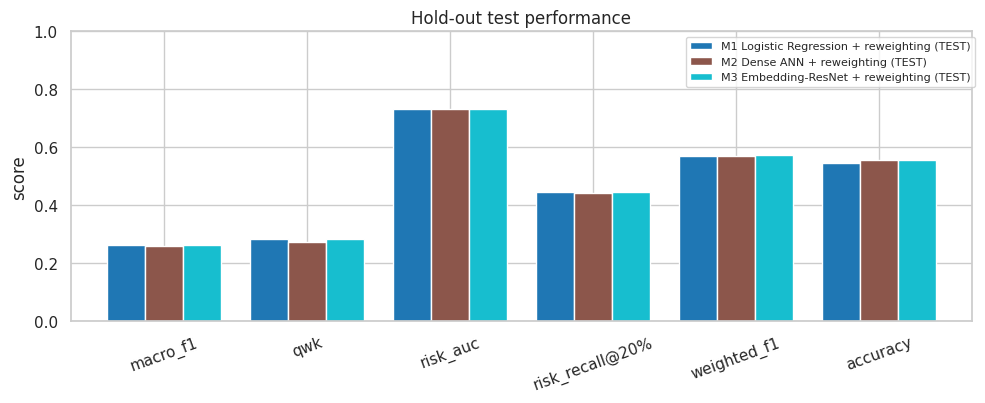

,macro_f1,qwk,risk_auc,risk_recall@20%,weighted_f1,accuracy
M1 Logistic Regression + reweighting (TEST),0.264,0.282,0.732,0.445,0.569,0.548
M2 Dense ANN + reweighting (TEST),0.260,0.273,0.732,0.444,0.572,0.557
M3 Embedding-ResNet + reweighting (TEST),0.262,0.283,0.734,0.445,0.574,0.557


In [62]:
# Cross-validated and test comparison
cv_table = pd.DataFrame({"Model 1 LogReg": cv_lr.mean(), "Model 2 Dense ANN": cv_dense.mean(), "Model 3 Embedding-ResNet": cv_emb.mean()}).T
cv_std = pd.DataFrame({"Model 1 LogReg": cv_lr.std(), "Model 2 Dense ANN": cv_dense.std(), "Model 3 Embedding-ResNet": cv_emb.std()}).T
print("3-fold cross-validation on the training set (mean):"); display(cv_table.round(4))
print("\n... and fold-to-fold standard deviation:"); display(cv_std.round(4))

names = ["M1 Logistic Regression + reweighting (TEST)", "M2 Dense ANN + reweighting (TEST)", "M3 Embedding-ResNet + reweighting (TEST)"]
print("\nHold-out TEST set (class re-weighting applied for the label metrics):")
test_table = metric_chart(names, "Hold-out test performance")
display(test_table)

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

We selected metrics for what an early-warning system needs. **Primary:** the **ROC-AUC** and the **top-20 % recall** of the dissatisfaction score, because the practical use is *ranking tickets for a limited-capacity team*, and these two do not depend on a threshold. **Secondary:** **quadratic weighted kappa** (respects the ordinal scale and is zero for chance-level models) and **macro-F1** (forces the model to care about the rare low scores). **Reported but not used for selection:** accuracy and weighted-F1, both dominated by the 69 % of 5-star tickets, and MAE, which rewards predicting "5" for everyone. The model-selection score was 0.5 x macro-F1 + 0.5 x QWK, and the final comparison was made on 3-fold cross-validation (training data only) before the test set was opened.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

**Chosen: Model 3 (embedding + residual ANN)** - but the evidence has to be read honestly. On cross-validation the three models are statistically tied: AUC 0.7216 (LogReg), 0.7194 (Dense ANN) and 0.7213 (Model 3), QWK 0.233 / 0.239 / 0.2415, with fold-to-fold standard deviations of 0.003-0.010. On the untouched test set Model 3 also comes out marginally ahead (AUC 0.734 vs 0.732, QWK 0.283 vs 0.282 vs 0.273), but these gaps are well inside noise. We still prefer Model 3 because (i) it has the highest mean CV QWK and the lowest variance across folds and the best test AUC, (ii) its embeddings handle the long-tailed categoricals (57 sub-categories, 1,783 cities) and unseen levels gracefully, and (iii) it is the architecture that can absorb additional inputs later (e.g. text embeddings, once a real-time text source exists).

**What we are *not* claiming:** that deep learning beats a linear model here. It does not, by any practically relevant margin. If simplicity, speed or auditability mattered more than the project's deep-learning objective, the tuned logistic regression would be a perfectly defensible production choice. The ordinal hybrid loss was also tried and did not win the search.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

The final model is the **Embedding + Residual ANN** (details above). To explain it we use **permutation importance** - model-agnostic and valid for any network: shuffle one feature (or one *group* of strongly related features, rows permuted together), re-score the untouched test set and measure how much the "dissatisfied" detector's ROC-AUC and the kappa degrade. A big drop = the model relies on that information.

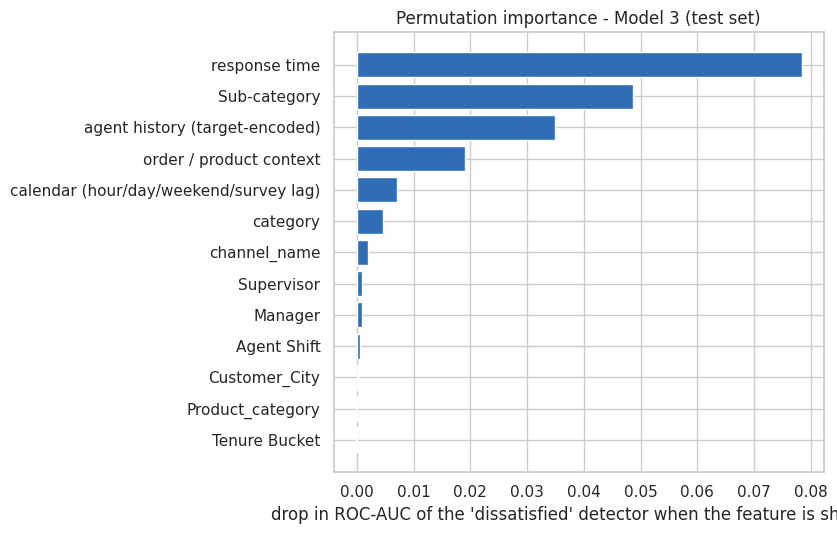

,feature group,drop in risk-AUC,drop in QWK
0,response time,0.0784,0.1117
1,Sub-category,0.0487,0.0451
2,agent history (target-encoded),0.0350,0.0502
3,order / product context,0.0190,0.0315
4,calendar (hour/day/weekend/survey lag),0.0070,0.0077
5,category,0.0046,0.0057
6,channel_name,0.0020,0.0035
7,Supervisor,0.0009,0.0018
8,Manager,0.0008,0.0003
9,Agent Shift,0.0005,0.0007


In [63]:
# Permutation importance on the hold-out test set (grouped features, 3 repeats)
final_pipe = final_emb["pipeline"]; final_pipe.class_weights = w_emb
GROUPS = {"response time": ["response_min", "log_response_min", "resp_negative_flag"],
          "order / product context": ["has_order_info", "order_to_issue_days", "log_item_price", "has_order_id"],
          "calendar (hour/day/weekend/survey lag)": ["rep_hour", "rep_dow", "rep_day", "is_weekend", "survey_lag_days"],
          "agent history (target-encoded)": [AGENT_COL]}
for c in CAT_COLS: GROUPS[c] = [c]

def perm_importance(pipe, X, yy, groups, repeats=3):
    base = evaluate(yy, pipe.predict_proba(X), pipe.class_weights); rng = np.random.default_rng(SEED); rows = []
    for g, cols in groups.items():
        drops_auc, drops_qwk = [], []
        for _ in range(repeats):
            Xp = X.copy(); perm = rng.permutation(len(X)); Xp[cols] = X[cols].values[perm]       # same permutation for the whole group
            m = evaluate(yy, pipe.predict_proba(Xp), pipe.class_weights)
            drops_auc.append(base["risk_auc"] - m["risk_auc"]); drops_qwk.append(base["qwk"] - m["qwk"])
        rows.append({"feature group": g, "drop in risk-AUC": np.mean(drops_auc), "drop in QWK": np.mean(drops_qwk)})
    return pd.DataFrame(rows).sort_values("drop in risk-AUC")

imp = perm_importance(final_pipe, X_te, y_te, GROUPS)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(imp["feature group"], imp["drop in risk-AUC"], color=BLUE)
ax.set_xlabel("drop in ROC-AUC of the 'dissatisfied' detector when the feature is shuffled"); ax.set_title("Permutation importance - Model 3 (test set)")
plt.tight_layout(); plt.show()
imp.sort_values("drop in risk-AUC", ascending=False).round(4).reset_index(drop=True)

**Reading the chart (drop in the detector's AUC when a feature group is shuffled, 3 repeats):**

1. **Response time - by far the most important (AUC drop 0.078)**, matching EDA Charts 8/15 and the what-if analysis below.
2. **Sub-category (0.049)** - the specific issue (for example Seller Cancelled Order at 30 % dissatisfied and Installation/demo at 23 %, versus Return request at 5.5 %) matters more than the broad category (0.005, whose information is largely contained in the sub-category).
3. **Agent history (0.035)** - the target-encoded agent statistics carry genuine signal, consistent with Chart 15 (agent variation twice what chance would produce).
4. **Order / product context (0.019)** - order-linked tickets and price.
5. **Calendar (0.007), channel (0.002)** and the staff hierarchy (supervisor, manager, shift, tenure, all below 0.001) add little *once the other features are known*. Note this does **not** contradict the EDA: e-mail, tenure and shift look important marginally, but they overlap with sub-category, agent history and response time, so shuffling them alone costs almost nothing. City and product category have no measurable importance (their slightly negative values are noise).

**Business interpretation:** to improve satisfaction, work on *speed* first, then on the specific problem types and on the individual-agent tail; reorganising shifts or tenure mix is unlikely to be the main lever.

*Caveat:* permutation importance shows what the model relies on, not causal effects, and correlated features share credit.

### Evaluation of the final model: confusion matrix, ROC curve and calibration of the risk score

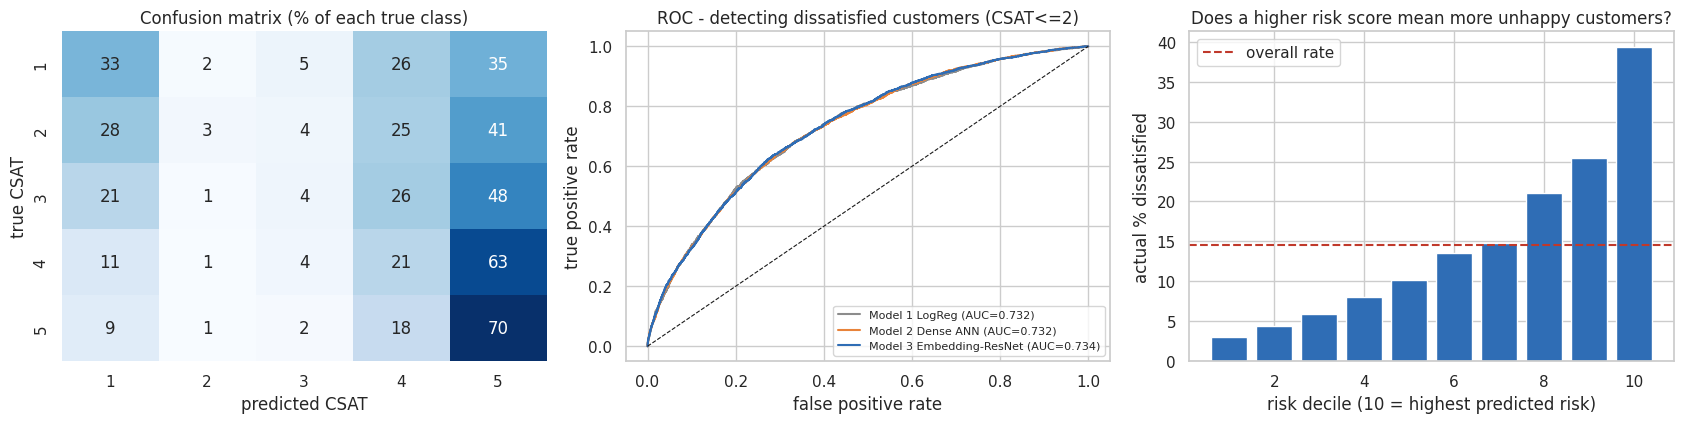

              precision    recall  f1-score   support

           1      0.330     0.331     0.331      2246
           2      0.040     0.031     0.035       256
           3      0.047     0.043     0.045       512
           4      0.139     0.210     0.167      2244
           5      0.766     0.698     0.731     11924

    accuracy                          0.557     17182
   macro avg      0.264     0.263     0.262     17182
weighted avg      0.595     0.557     0.574     17182

Actual dissatisfaction rate in the riskiest decile: 39.3%  vs  safest decile: 3.0%


In [64]:
# Final model diagnostics on the test set
pred_te = (final_emb["proba"] * w_emb).argmax(1) + 1
cm = confusion_matrix(y_te, pred_te, labels=[1, 2, 3, 4, 5], normalize="true") * 100
risk_te = final_emb["proba"][:, 0] + final_emb["proba"][:, 1]; low_te = (y_te <= 2).astype(int)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5], ax=axes[0], cbar=False)
axes[0].set_xlabel("predicted CSAT"); axes[0].set_ylabel("true CSAT"); axes[0].set_title("Confusion matrix (% of each true class)")
for name, p, c in [("Model 1 LogReg", p_te_lr, GREY), ("Model 2 Dense ANN", final_dense["proba"], ORANGE), ("Model 3 Embedding-ResNet", final_emb["proba"], BLUE)]:
    fpr, tpr, _ = roc_curve(low_te, p[:, 0] + p[:, 1]); axes[1].plot(fpr, tpr, color=c, label=f"{name} (AUC={roc_auc_score(low_te, p[:, 0] + p[:, 1]):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=.8); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].legend(fontsize=8)
axes[1].set_title("ROC - detecting dissatisfied customers (CSAT<=2)")
dec = pd.qcut(risk_te, 10, labels=False, duplicates="drop") + 1
lift = pd.DataFrame({"decile": dec, "low": low_te}).groupby("decile")["low"].mean() * 100
axes[2].bar(lift.index, lift.values, color=BLUE); axes[2].axhline(low_te.mean() * 100, color=RED, ls="--", label="overall rate")
axes[2].set_xlabel("risk decile (10 = highest predicted risk)"); axes[2].set_ylabel("actual % dissatisfied"); axes[2].set_title("Does a higher risk score mean more unhappy customers?"); axes[2].legend()
plt.tight_layout(); plt.show()
print(classification_report(y_te, pred_te, digits=3, zero_division=0))
print("Actual dissatisfaction rate in the riskiest decile: {:.1%}  vs  safest decile: {:.1%}".format(lift.iloc[-1] / 100, lift.iloc[0] / 100))

**Confusion matrix:** the model recovers 1-star tickets reasonably well (recall 33 %, precision 33 %), 5-star tickets best (recall 70 %, precision 77 %), but **scores 2 and 3 are practically unpredictable (F1 0.04)**: they are rare (1.5 % and 3 %) and are the ambiguous middle of a polarised distribution. Most errors are to adjacent scores, which is why QWK is more forgiving than accuracy.

**ROC curves:** the three models lie on top of each other (AUC 0.732-0.734), confirming the tie.

**Risk deciles (right plot):** this is the most useful picture. Actual dissatisfaction rises steadily with the predicted risk decile, from **3.0 % in the safest decile to 39.3 % in the riskiest** (overall 14.6 %): the score *ranks* customers well even though exact-score prediction is hard. This is the basis for the HIGH / MEDIUM / LOW tiers used in deployment.

### Innovation experiment: how much would the customer's own remarks add? (upper bound - *not* deployable)

The remark text is only available *after* the survey, so this is a **diagnostic upper bound**, not a production model. It shows how much of the unexplained variance is "voice of the customer" rather than operational metadata.

In [65]:
# Upper-bound experiment: Model 3 configuration + remark features (leakage by design, for diagnosis only)
extra = list(rem.columns)
X_tr_r, X_te_r = X_tr.join(rem), X_te.join(rem)
r_leak = fit_ann("embed", best_emb_cfg, X_tr_r, y_tr, X_te_r, extra_num=extra)
log_result("UPPER BOUND with remarks (TEST, not deployable)", y_te, r_leak["proba"])
w_leak = tune_class_weights(y_tr, oof_emb)   # reuse the production weights for a like-for-like comparison
log_result("UPPER BOUND + reweighting (TEST)", y_te, r_leak["proba"], w_leak)
display(pd.DataFrame({"production Model 3": RESULTS["M3 Embedding-ResNet + reweighting (TEST)"], "with remarks (leaky)": RESULTS["UPPER BOUND + reweighting (TEST)"]}).round(3).T)

UPPER BOUND with remarks (TEST, not deployable)accuracy=0.703  macro_f1=0.259  weighted_f1=0.634  qwk=0.390  mae=0.741  risk_auc=0.806  risk_recall@20%=0.562


UPPER BOUND + reweighting (TEST)          accuracy=0.594  macro_f1=0.300  weighted_f1=0.611  qwk=0.413  mae=0.816  risk_auc=0.806  risk_recall@20%=0.562


,accuracy,macro_f1,weighted_f1,qwk,mae,risk_auc,risk_recall@20%
production Model 3,0.557,0.262,0.574,0.283,0.936,0.734,0.445
with remarks (leaky),0.594,0.300,0.611,0.413,0.816,0.806,0.562


Adding the lexicon features from the customer's remarks lifts the detector's AUC from **0.734 to 0.806**, QWK from **0.283 to 0.413**, and the top-20 % recall from **44.5 % to 56.2 %**, even though only 33 % of customers write a remark. So the customer's own words explain a good part of what the operational metadata cannot - but they exist only after the survey, so this model **must not be deployed** as a real-time predictor. The practical lesson: if Shopzilla can capture *any* earlier voice-of-customer signal (a chat message, an in-call sentiment score, a one-tap thumbs-up at ticket closure), it would be the highest-value addition to this model. It also shows the 0.73 AUC is not a modelling failure but an information ceiling.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [66]:
# Save the File: Keras model + fitted preprocessor + metadata, all in ./deployment (a self-contained, portable folder)
import shutil
os.makedirs("deployment", exist_ok=True)
fp = final_emb["pipeline"]
fp.model.save("deployment/csat_model.keras")
joblib.dump(fp.pre, "deployment/preprocessor.joblib")
shutil.copy("csat_utils.py", "deployment/csat_utils.py")

risk_oof = oof_emb[:, 0] + oof_emb[:, 1]
cat_levels = {c: sorted(feat[c].unique().tolist()) for c in CAT_COLS}
meta = {"model": "Embedding-ResNet ANN (Model 3)", "n_cat": int(fp.n_cat), "offsets": fp.offsets.tolist(),
        "class_weights": [float(w) for w in w_emb], "best_config": best_emb_cfg,
        "risk_thresholds": {"medium": float(np.quantile(risk_oof, 0.70)), "high": float(np.quantile(risk_oof, 0.90))},
        "test_metrics": {k: float(v) for k, v in RESULTS["M3 Embedding-ResNet + reweighting (TEST)"].items()},
        "categorical_levels": cat_levels, "trained_on": "Shopzilla support tickets, Aug 2023"}
json.dump(meta, open("deployment/meta.json", "w"), indent=2)
print(sorted(os.listdir("deployment")))

['csat_model.keras', 'csat_utils.py', 'meta.json', 'preprocessor.joblib']


In [67]:
%%writefile deployment/predict.py
"""Score new Shopzilla support tickets locally.

Usage:   python predict.py tickets.csv scored.csv
Input :  a CSV with the same raw columns as eCommerce_Customer_support_data.csv (CSAT Score is NOT needed).
Output:  the input row ids + predicted CSAT, P(each score), P(dissatisfied) and a risk tier.
"""
import os, sys, json
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
HERE = os.path.dirname(os.path.abspath(__file__)); sys.path.insert(0, HERE)

import numpy as np, pandas as pd, joblib
from tensorflow import keras
from csat_utils import engineer, AnnPipeline, RAW_INPUT_COLS

_CACHE = {}

def load_pipeline():
    """Load (and cache) preprocessor + model + metadata."""
    if not _CACHE:
        meta = json.load(open(os.path.join(HERE, "meta.json")))
        pre = joblib.load(os.path.join(HERE, "preprocessor.joblib"))
        model = keras.models.load_model(os.path.join(HERE, "csat_model.keras"), compile=False)
        _CACHE["pipe"] = AnnPipeline(pre, model, "embed", meta["n_cat"], meta["class_weights"], meta["offsets"])
        _CACHE["meta"] = meta
    return _CACHE["pipe"], _CACHE["meta"]

def score_dataframe(raw: pd.DataFrame) -> pd.DataFrame:
    """Raw ticket rows in -> scored DataFrame out. Missing optional columns are treated as 'not available'."""
    pipe, meta = load_pipeline()
    raw = raw.copy()
    for c in RAW_INPUT_COLS:
        if c not in raw.columns:
            raw[c] = np.nan
    proba = pipe.predict_proba(engineer(raw))
    risk = proba[:, 0] + proba[:, 1]
    th = meta["risk_thresholds"]
    out = pd.DataFrame(proba, columns=[f"p_csat_{k}" for k in range(1, 6)], index=raw.index).round(4)
    out.insert(0, "predicted_csat", pipe.predict(engineer(raw)))
    out.insert(1, "expected_csat", (proba * np.arange(1, 6)).sum(1).round(2))
    out["p_dissatisfied"] = risk.round(4)
    out["risk_tier"] = np.where(risk >= th["high"], "HIGH", np.where(risk >= th["medium"], "MEDIUM", "LOW"))
    if "Unique id" in raw.columns:
        out.insert(0, "Unique id", raw["Unique id"].values)
    return out

if __name__ == "__main__":
    if len(sys.argv) != 3:
        sys.exit(__doc__)
    scored = score_dataframe(pd.read_csv(sys.argv[1]))
    scored.to_csv(sys.argv[2], index=False)
    print(scored.head(10).to_string(index=False))
    print(f"\nScored {len(scored):,} tickets -> {sys.argv[2]}  |  risk tiers: {scored.risk_tier.value_counts().to_dict()}")

Writing deployment/predict.py


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [68]:
# Load the File and predict unseen data - in a SEPARATE Python process (what a real deployment does)
import subprocess
unseen = raw.loc[X_te.index[:2000]].drop(columns=["CSAT Score"])                 # pretend these are brand-new tickets without a label
unseen.to_csv("unseen_tickets.csv", index=False)
res = subprocess.run([sys.executable, "deployment/predict.py", "unseen_tickets.csv", "scored_tickets.csv"], capture_output=True, text=True)
print(res.stdout[-1800:]); print(res.stderr[-400:] if res.returncode else "")
assert res.returncode == 0, "deployment script failed"

# Consistency check: the re-loaded model must reproduce the in-memory predictions
scored = pd.read_csv("scored_tickets.csv")
ref = (final_emb["proba"][:2000, 0] + final_emb["proba"][:2000, 1])
print("max |difference| between re-loaded and in-memory P(dissatisfied):", float(np.abs(scored["p_dissatisfied"].values - ref).max()))
assert np.abs(scored["p_dissatisfied"].values - ref).max() < 1e-3
print("Sanity check passed. Share of tickets per risk tier:", scored["risk_tier"].value_counts(normalize=True).round(3).to_dict())
print("Actual dissatisfaction rate by predicted tier:",
      pd.Series(y_te[:2000] <= 2).groupby(scored["risk_tier"].values).mean().round(3).to_dict())

                           Unique id  predicted_csat  expected_csat  p_csat_1  p_csat_2  p_csat_3  p_csat_4  p_csat_5  p_dissatisfied risk_tier
29dd9759-545f-4045-abc4-6a4f0eced573               5           3.95    0.1095    0.0807    0.0770    0.2187    0.5140          0.1903       LOW
677882ca-a1bc-4388-b17e-ae988aa31923               5           4.46    0.0371    0.0397    0.0461    0.1758    0.7013          0.0768       LOW
753e326b-04de-4d9d-a6f5-89516d115728               5           3.89    0.1340    0.0537    0.0945    0.2251    0.4927          0.1877       LOW
6049b6ab-8e1d-4622-bcf6-ec011d711144               5           4.00    0.1228    0.0367    0.0695    0.2644    0.5067          0.1594       LOW
64d5c2ff-769d-40ff-8b3e-75d62d0968e2               1           3.11    0.2929    0.0884    0.1394    0.1779    0.3014          0.3813    MEDIUM
1d32c05d-d9cb-401d-8c06-e47bf3d60824               5           3.86    0.1411    0.0612    0.0873    0.2196    0.4908          0.2022   

### What-if analysis: what does the model say about response time?

To turn the model into an *insight* tool, we take 1,000 unseen tickets and **re-score each one as if it had been answered after X minutes**, leaving everything else unchanged. This is a model-implied association (not proof of causation, because slow tickets are also harder tickets), but it quantifies the operational lever for the business.

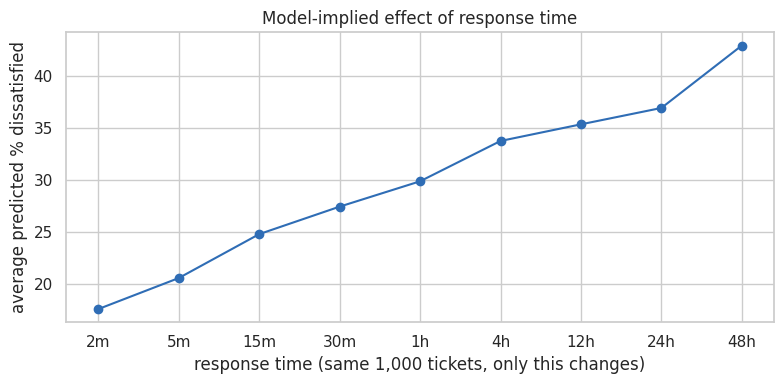

{'2m': np.float32(17.5), '5m': np.float32(20.5), '15m': np.float32(24.8), '30m': np.float32(27.4), '1h': np.float32(29.8), '4h': np.float32(33.7), '12h': np.float32(35.3), '24h': np.float32(36.9), '48h': np.float32(42.9)}


In [69]:
# What-if: average predicted probability of dissatisfaction if every ticket were answered after X minutes
sys.path.insert(0, "deployment")
import predict as deploy
sample = raw.loc[X_te.index[:1000]].drop(columns=["CSAT Score"]).copy()
reported = pd.to_datetime(sample["Issue_reported at"], format="%d/%m/%Y %H:%M")
mins = [2, 5, 15, 30, 60, 240, 720, 1440, 2880]
risk_by_minutes = []
for m in mins:
    s = sample.copy(); s["issue_responded"] = (reported + pd.Timedelta(minutes=m)).dt.strftime("%d/%m/%Y %H:%M")
    risk_by_minutes.append(deploy.score_dataframe(s)["p_dissatisfied"].mean() * 100)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(len(mins)), risk_by_minutes, marker="o", color=BLUE)
ax.set_xticks(range(len(mins))); ax.set_xticklabels(["2m", "5m", "15m", "30m", "1h", "4h", "12h", "24h", "48h"])
ax.set_xlabel("response time (same 1,000 tickets, only this changes)"); ax.set_ylabel("average predicted % dissatisfied")
ax.set_title("Model-implied effect of response time"); plt.tight_layout(); plt.show()
print(dict(zip(["2m", "5m", "15m", "30m", "1h", "4h", "12h", "24h", "48h"], np.round(risk_by_minutes, 1))))

**Reading the curve:** holding everything else fixed, the model's average predicted probability of dissatisfaction rises from about **17.5 % at 2 minutes to 29.8 % at 1 hour, 36.9 % at 24 hours and 42.9 % at 48 hours** - the same gradient seen in EDA Chart 8, now learned from all features jointly. It suggests that cutting the long waits is worth far more than shaving seconds off fast answers, but it remains an association, not a controlled experiment.

### Optional: a small local web app (Streamlit) for the video demo

`deployment/app.py` lets a supervisor describe a ticket in a form and see the predicted CSAT, the probability of dissatisfaction and the risk tier. Run it locally with:

```
pip install -r requirements.txt
streamlit run deployment/app.py
```

In [70]:
%%writefile deployment/app.py
"""Local demo UI:  streamlit run deployment/app.py"""
import os, sys, json
import pandas as pd
import streamlit as st
HERE = os.path.dirname(os.path.abspath(__file__)); sys.path.insert(0, HERE)
import predict

st.set_page_config(page_title="Shopzilla CSAT predictor", layout="centered")
st.title("Shopzilla - CSAT risk predictor")
meta = json.load(open(os.path.join(HERE, "meta.json")))
lv = meta["categorical_levels"]

c1, c2 = st.columns(2)
channel = c1.selectbox("Channel", lv["channel_name"]); category = c2.selectbox("Category", lv["category"])
sub = c1.selectbox("Sub-category", lv["Sub-category"]); product = c2.selectbox("Product category", lv["Product_category"])
tenure = c1.selectbox("Agent tenure", lv["Tenure Bucket"]); shift = c2.selectbox("Agent shift", lv["Agent Shift"])
manager = c1.selectbox("Manager", lv["Manager"]); supervisor = c2.selectbox("Supervisor", lv["Supervisor"])
agent = st.text_input("Agent name (optional - unknown agents use the average)", "")
resp = st.slider("Response time (minutes)", 0, 2880, 10)
price = st.number_input("Item price (0 = not an order ticket)", 0, 200000, 0)
hour = st.slider("Hour the issue was reported", 0, 23, 12)

if st.button("Predict"):
    rep = pd.Timestamp.now().normalize() + pd.Timedelta(hours=hour)
    row = pd.DataFrame([{"channel_name": channel, "category": category, "Sub-category": sub, "Product_category": product,
                         "Tenure Bucket": tenure, "Agent Shift": shift, "Manager": manager, "Supervisor": supervisor,
                         "Agent_name": agent or None, "Item_price": price or None,
                         "Issue_reported at": rep.strftime("%d/%m/%Y %H:%M"),
                         "issue_responded": (rep + pd.Timedelta(minutes=resp)).strftime("%d/%m/%Y %H:%M"),
                         "Survey_response_Date": rep.strftime("%d-%b-%y")}])
    out = predict.score_dataframe(row).iloc[0]
    st.metric("Predicted CSAT", int(out["predicted_csat"]), help=f"Expected score {out['expected_csat']}")
    st.metric("Probability customer is dissatisfied (CSAT<=2)", f"{out['p_dissatisfied']:.0%}")
    st.subheader(f"Risk tier: {out['risk_tier']}")
    st.bar_chart(pd.Series({k: out[f"p_csat_{k}"] for k in range(1, 6)}, name="probability"))

Writing deployment/app.py


# **Conclusion**\n\n**What we did.** We cleaned and parsed a month of Shopzilla support tickets, engineered response-time, calendar, order-context and agent-history features without leaking the target, explored the data with 18 charts and 3 hypothesis tests, and trained three models (logistic regression, dense ANN, embedding + residual ANN with an optional ordinal-aware loss) with early stopping, class weighting, random-search tuning and cross-validation. The best model was packaged and verified in a separate Python process.

**What we found.**
* Response time is the dominant lever: dissatisfaction climbs from 8.9 % (within 5 minutes) to 36.3 % (over 24 hours), and the model implies the same gradient.
* The ANNs do **not** beat logistic regression in any practically meaningful way (test AUC 0.732-0.734, QWK 0.27-0.28); tuning and the ordinal loss gave no measurable improvement. Ticket metadata alone caps predictability; the remarks experiment (AUC 0.806) shows the missing information is the customer's own voice.
* Even so, the risk score is operationally valuable: the top decile has a 39 % dissatisfaction rate versus 3 % in the bottom decile.

**Recommendations.** Set and monitor a first-response SLA (about 15 minutes), escalate HIGH-risk tickets, review e-mail handling and the Cancellation/Order-related categories, and give extra support to trainee agents and the Morning shift.

**Limitations.** One month of data (so a random split rather than a time split, with a visible upward drift in satisfaction); scores 2 and 3 are not predictable; agent features cannot help brand-new agents; the Streamlit demo was not run in a browser during development. **Next steps:** retrain monthly, add an earlier voice-of-customer signal, calibrate the probabilities, and evaluate with a proper time-based hold-out once more months are available.\n\n### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***